# Construção e avaliação dos classificadores

**Entrega: 21/11/2026 | Valor: 4,00 pontos.**

A seção do Membro 1 (Árvore de Decisão e protocolo comum) está implementada; as demais permanecem como roteiro de trabalho. As seções seguintes devem executar depois dela, pois reutilizam a carga, as dobras e o avaliador comum. Substituir Membro 1–5 pelos nomes do grupo do CANVAS.


## Regras comuns às cinco tarefas

- Usar os CSVs oficiais em `data/`: `treino.csv`, `teste_sem_rotulo.csv` e `modelo_de_submissao.csv`.
- O alvo é `class`, com valores `normal` e `anomaly`; não remapear para cinco famílias de ataques.
- Não substituir, reembaralhar ou recriar a separação oficial de treino/teste. Validação interna é permitida **somente dentro do treino**.
- Ajustar imputação, codificação, normalização, balanceamento e redução apenas no treino de cada dobra.
- `id` identifica o teste e não é atributo preditivo. O teste não tem gabarito disponível à equipe.
- Investigar a associação de **cada atributo** com a classe antes de treinar modelos. Correlação alta não prova vazamento sozinha.
- Examinar também as colunas adicionadas, inclusive `score_ids_legado`, `tipo_alerta_soc` e `tempo_resposta_analista_min`; justificar decisões pela origem e disponibilidade da informação.
- Não reutilizar conclusões ou números da base antiga. Não procurar/reconstruir rótulos do teste público.
- Os módulos em `src/` são a estrutura legada e precisam ser adaptados pelos responsáveis; este roteiro não os executa.
- Cada membro deve produzir código comentado, resultados e uma conclusão autoral em sua seção, além de revisar a integração.


## Membro 1 - Árvore de Decisão e protocolo comum

**Tarefa:** Definir com a equipe as dobras internas, sementes, métricas e combinações recebidas da etapa 2. Implementar Árvore de Decisão e avaliá-la nas estratégias escolhidas, sem usar o teste. Compartilhar as mesmas divisões com os membros 2 e 3.

**Entregável:** Resultados por configuração e dobra, parâmetros documentados e análise dos erros de ambas as classes.


### 1.1 Protocolo da etapa 3

O protocolo abaixo serve para os três classificadores (Membros 1, 2 e 3). Ele resume exatamente a carga, as transformações e as dobras do notebook 02, para que os resultados das etapas sejam comparáveis.

| Item | Decisão comum | Motivo |
|---|---|---|
| Dados | Somente data/treino.csv, o teste oficial não é lido nesta seção | Sem gabarito e sem decisões guiadas pelo teste |
| Preditores | 46 atributos, sinais operacionais (score_ids_legado, tipo_alerta_soc, tempo_resposta_analista_min) excluídos | Risco de vazamento apontado nas etapas 1 e 2, decisão final do Membro 5 |
| Dobras | StratifiedGroupKFold, 5 dobras, shuffle=True, semente 42, grupo = registro com atributos idênticos | Cópias nunca ficam em lados opostos, mesmas dobras da etapa 2 |
| Sementes | semente = 42 em dobras, amostradores e modelos | Reprodutibilidade |
| Ajustes | Imputação, codificação, escala, filtro de conflitos e balanceamento apenas no treino de cada dobra, a validação nunca é filtrada nem balanceada | Sem vazamento e estimativa honesta |
| Métrica principal | F1-macro na validação de cada dobra (média ± desvio entre dobras) | Critério do trabalho |
| Métricas complementares | Precisão, recall e F1 por classe, acurácia, matriz de confusão (TN, FP, FN, TP) e tempos de ajuste/predição | Análise de erros e custo |

As funções avaliar_modelo, montar_pipeline, os dicionários CONFIGURACOES e a lista INDICES_DOBRAS ficam para as seções seguintes.

In [1]:
# Membro 1 - 1.1 Protocolo comum: carga, transformações e dobras (iguais às do notebook 02)
from pathlib import Path
import hashlib
import platform
import time

import numpy as np
import pandas as pd
import sklearn
import imblearn
from IPython.display import display
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as PipelineBalanceado
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

print({"Python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__})

SEMENTE = 42
N_DOBRAS = 5

project_root = Path.cwd().resolve()
if not (project_root / "data" / "treino.csv").exists():
    project_root = project_root.parent
if not (project_root / "data" / "treino.csv").exists():
    raise FileNotFoundError("Execute na raiz do projeto ou em notebooks/.")
DIR_DADOS = project_root / "data"

COL_ROTULO = "class"
COL_ID = "id"
CLASSES = ["normal", "anomaly"]          # anomaly = classe positiva (1)
COLS_CATEGORICAS = ["protocol_type", "service", "flag"]
SINAIS_OPERACIONAIS = ["score_ids_legado", "tipo_alerta_soc", "tempo_resposta_analista_min"]
COLS_DERIVADAS = ("src_bytes_kb", "dst_bytes_kb", "total_bytes", "same_srv_pct", "protocolo_cod")
# Limites de domínio da documentação do KDD (conhecimento prévio, não aprendidos dos dados).
LIMITES_DOMINIO = {
    **{c: (0, 1) for c in ["serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
                           "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate",
                           "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
                           "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
                           "dst_host_serror_rate", "dst_host_srv_serror_rate",
                           "dst_host_rerror_rate", "dst_host_srv_rerror_rate"]},
    "same_srv_pct": (0, 100),
    "count": (0, 511), "srv_count": (0, 511),
    "dst_host_count": (0, 255), "dst_host_srv_count": (0, 255),
    "duration": (0, np.inf), "src_bytes": (0, np.inf), "dst_bytes": (0, np.inf),
    "total_bytes": (0, np.inf), "src_bytes_kb": (0, np.inf), "dst_bytes_kb": (0, np.inf),
}


def carregar_treino(incluir_operacionais: bool = False):
    """Lê treino.csv sem alterá-lo. Retorna (X, y) com y = 1 para anomaly."""
    df = pd.read_csv(DIR_DADOS / "treino.csv")
    assert set(df[COL_ROTULO]) == set(CLASSES) and df[COL_ROTULO].notna().all()
    assert COL_ID not in df.columns, "id não é atributo preditivo."
    descartar = [COL_ROTULO] + ([] if incluir_operacionais else SINAIS_OPERACIONAIS)
    return df.drop(columns=descartar), (df[COL_ROTULO] == "anomaly").astype(int).rename(COL_ROTULO)


class NormalizarCategorias(BaseEstimator, TransformerMixin):
    """strip + minúsculas nos categóricos ('TCP ' -> 'tcp'). Sem estado; NaN continua NaN."""

    def __init__(self, colunas=tuple(COLS_CATEGORICAS), ativo=True):
        self.colunas = colunas
        self.ativo = ativo

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        for c in self.colunas:
            if c in X:
                serie = X[c].astype(object)
                X[c] = serie.str.strip().str.lower() if self.ativo else serie
        return X


class TratarForaDominio(BaseEstimator, TransformerMixin):
    """'manter' | 'ausente' (vira NaN) | 'recorte' (clip). Limites da documentação."""

    def __init__(self, modo="manter"):
        self.modo = modo

    def fit(self, X, y=None):
        assert self.modo in {"manter", "ausente", "recorte"}
        return self

    def transform(self, X):
        if self.modo == "manter":
            return X
        X = X.copy()
        for c, (lo, hi) in LIMITES_DOMINIO.items():
            if c in X:
                X[c] = (X[c].astype(float).mask((X[c] < lo) | (X[c] > hi)) if self.modo == "ausente"
                        else X[c].clip(lower=lo, upper=hi))
        return X


class RemoverRedundantes(BaseEstimator, TransformerMixin):
    """Remove derivadas determinísticas (lista fixa) e constantes detectadas NO TREINO DA DOBRA."""

    def __init__(self, ativo=True):
        self.ativo = ativo

    def fit(self, X, y=None):
        constantes = [c for c in X.columns if X[c].nunique(dropna=True) <= 1] if self.ativo else []
        self.remover_ = sorted(set(COLS_DERIVADAS).intersection(X.columns) | set(constantes)) if self.ativo else []
        return self

    def transform(self, X):
        return X.drop(columns=self.remover_)


def _eh_categorica(X):
    return [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]


def _eh_numerica(X):
    return [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]


def montar_preprocessamento(normalizar_categorias=True, fora_dominio="manter", remover_redundantes=False,
                            imputacao_num="mediana", imputacao_cat="constante",
                            codificacao="onehot", escala=None):
    """Pré-processamento das partes 1 e 3 do notebook 02, com codificação e escala selecionáveis.

    codificacao: 'onehot' | 'onehot_raras' (categorias com < 100 registros no treino da dobra agrupadas)
    escala:      None | 'standard'  (árvores não precisam; útil para a MLP do Membro 3)
    """
    imp_num = SimpleImputer(strategy="median", add_indicator=(imputacao_num == "mediana+indicador"))
    numerico = Pipeline([("imp", imp_num), ("escala", StandardScaler() if escala == "standard" else "passthrough")])
    imp_cat = (SimpleImputer(strategy="constant", fill_value="__ausente__") if imputacao_cat == "constante"
               else SimpleImputer(strategy="most_frequent"))
    ohe = (OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False)
           if codificacao == "onehot_raras" else OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    colunas = ColumnTransformer([
        ("num", numerico, _eh_numerica),
        ("cat", Pipeline([("imp", imp_cat), ("ohe", ohe)]), _eh_categorica),
    ], verbose_feature_names_out=False)
    return Pipeline([
        ("categorias", NormalizarCategorias(ativo=normalizar_categorias)),
        ("dominio", TratarForaDominio(modo=fora_dominio)),
        ("redundantes", RemoverRedundantes(ativo=remover_redundantes)),
        ("imputacao_codificacao", colunas),
    ])


def chave_registro(X):
    """Identificador de registros com atributos idênticos (categorias normalizadas, NaN como valor)."""
    Xn = NormalizarCategorias().transform(X)
    return pd.Series(pd.factorize(pd.util.hash_pandas_object(Xn, index=False))[0], index=X.index)


def filtrar_linhas_treino(X, y, estrategia="todas"):
    """'todas' | 'sem_conflitos': remove, só do treino da dobra, grupos idênticos com classes divergentes."""
    if estrategia == "todas":
        return X, y
    if estrategia != "sem_conflitos":
        raise ValueError(estrategia)
    chave = chave_registro(X)
    manter = ~chave.map(y.groupby(chave).nunique()).gt(1)
    return X[manter], y[manter]


X_treino, y_treino = carregar_treino()
grupos_treino = chave_registro(X_treino)
DOBRAS = StratifiedGroupKFold(n_splits=N_DOBRAS, shuffle=True, random_state=SEMENTE)
INDICES_DOBRAS = list(DOBRAS.split(X_treino, y_treino, grupos_treino))

# Auditoria das dobras: partição completa, grupos disjuntos e proporção de anomalias estável.
dobra_de_cada_linha = np.empty(len(X_treino), dtype=int)
auditoria_dobras = []
for i, (itr, iva) in enumerate(INDICES_DOBRAS, start=1):
    assert set(grupos_treino.iloc[itr]).isdisjoint(grupos_treino.iloc[iva])
    dobra_de_cada_linha[iva] = i
    auditoria_dobras.append({"dobra": i, "n_treino": len(itr), "n_validacao": len(iva),
                             "anomalias_validacao": int(y_treino.iloc[iva].sum()),
                             "pct_anomaly_validacao": 100 * y_treino.iloc[iva].mean()})
assert sorted(np.concatenate([iva for _, iva in INDICES_DOBRAS])) == list(range(len(X_treino)))
# Impressão digital das dobras: os Membros 2 e 3 (e o notebook 04) podem conferir que usam a mesma divisão.
ASSINATURA_DOBRAS = hashlib.sha256(dobra_de_cada_linha.tobytes()).hexdigest()[:16]

print(f"Treino: {X_treino.shape[0]:,} linhas x {X_treino.shape[1]} atributos; "
      f"{grupos_treino.nunique():,} registros distintos (grupos)")
print("Assinatura das dobras:", ASSINATURA_DOBRAS)
display(pd.DataFrame(auditoria_dobras).round(3))

{'Python': '3.12.3', 'numpy': '1.26.4', 'pandas': '3.0.5', 'scikit-learn': '1.9.0', 'imbalanced-learn': '0.14.2'}
Treino: 69,833 linhas x 46 atributos; 56,766 registros distintos (grupos)
Assinatura das dobras: 8a814c72d149c698


,dobra,n_treino,n_validacao,anomalias_validacao,pct_anomaly_validacao
0,1,55866,13967,816,5.842
1,2,55865,13968,816,5.842
2,3,55867,13966,816,5.843
3,4,55867,13966,816,5.843
4,5,55867,13966,815,5.836


### 1.2 Combinações recebidas da etapa 2 e avaliador comum

As combinações abaixo foram definidas a partir das conclusões do notebook 02. Cada uma altera **um fator** em relação à anterior, para que a diferença de desempenho possa ser atribuída a ele.

| Código | Pré-processamento | Balanceamento | Origem |
|---|---|---|---|
| P0 | Referência R0: categorias brutas, fora do domínio mantido, todas as colunas e linhas, One-Hot | nenhum | Parte 1 da etapa 2 (referência) |
| P1 | CONFIG_M1: categorias normalizadas, fora do domínio (ausente), sem derivadas/constantes, mediana + `__ausente__`, treino sem conflitos | nenhum | Combinação proposta pelo Membro 1 da etapa 2 |
| P2 | P1 + One-Hot com categorias raras (< 100 no treino da dobra) agrupadas | nenhum | Proposta do Membro 3 da etapa 2 |
| P3 | P2 | RandomOverSampler 1:1 | Membro 2 da etapa 2 |
| P4 | P2 | RandomUnderSampler 1:1 | Membro 2 da etapa 2 |

SMOTENC + Tomek não foi incluído, pois na etapa 2 ele não superou a ausência de balanceamento e custou cerca de 20 a 30 vezes mais por dobra.

In [ ]:
# Membro 1 - 1.2 Combinações da etapa 2 e avaliador comum (reutilizado pelos Membros 2 e 3)
CONFIG_R0 = dict(normalizar_categorias=False, fora_dominio="manter", remover_redundantes=False,
                 imputacao_num="mediana", imputacao_cat="constante", codificacao="onehot",
                 linhas_treino="todas", balanceamento=None)
CONFIG_M1 = dict(normalizar_categorias=True, fora_dominio="ausente", remover_redundantes=True,
                 imputacao_num="mediana", imputacao_cat="constante", codificacao="onehot",
                 linhas_treino="sem_conflitos", balanceamento=None)
CONFIGURACOES = {
    "P0 referência R0": CONFIG_R0,
    "P1 tratamento M1": CONFIG_M1,
    "P2 P1 + raras agrupadas": {**CONFIG_M1, "codificacao": "onehot_raras"},
    "P3 P2 + ROS": {**CONFIG_M1, "codificacao": "onehot_raras", "balanceamento": "ROS"},
    "P4 P2 + RUS": {**CONFIG_M1, "codificacao": "onehot_raras", "balanceamento": "RUS"},
}
CONFIG_PRINCIPAL = "P2 P1 + raras agrupadas"


def montar_pipeline(config, modelo, escala=None):
    """Pré-processamento + balanceamento opcional (só no fit) + modelo. Tudo é ajustado no treino da dobra."""
    prep_params = {k: v for k, v in config.items() if k not in ("linhas_treino", "balanceamento")}
    amostradores = {
        None: "passthrough",
        "ROS": RandomOverSampler(sampling_strategy=1.0, random_state=SEMENTE),
        "RUS": RandomUnderSampler(sampling_strategy=1.0, replacement=False, random_state=SEMENTE),
    }
    # imblearn não aceita Pipeline aninhado como etapa intermediária: as etapas do pré-processamento
    # entram "achatadas" (categorias, dominio, redundantes, imputacao_codificacao).
    prep = montar_preprocessamento(**prep_params, escala=escala)
    return PipelineBalanceado(prep.steps + [
        ("balanceamento", amostradores[config["balanceamento"]]),
        ("modelo", clone(modelo)),
    ])


def metricas_classificacao(y_true, y_pred):
    """F1-macro (principal), métricas por classe, acurácia e matriz de confusão (anomaly = positivo)."""
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    m = {"f1_macro": float(f.mean()), "acuracia": accuracy_score(y_true, y_pred),
         "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}
    for j, classe in enumerate(CLASSES):
        m.update({f"precisao_{classe}": p[j], f"recall_{classe}": r[j], f"f1_{classe}": f[j]})
    return m


def avaliar_modelo(modelo, nome_modelo, configuracoes=None, dobras=None, escala=None, guardar=False):
    """Protocolo comum: para cada combinação e dobra, ajusta no treino (filtrado) e mede na validação intacta.

    Retorna (por_dobra, oof): métricas por combinação * dobra e, se guardar=True, as predições fora da
    dobra e os pipelines ajustados por combinação (para análise de erros e importâncias).
    """
    configuracoes = CONFIGURACOES if configuracoes is None else configuracoes
    dobras = INDICES_DOBRAS if dobras is None else dobras
    linhas, oof = [], {}
    for nome_cfg, cfg in configuracoes.items():
        pred_oof = np.full(len(X_treino), -1)
        pipes = []
        for dobra, (itr, iva) in enumerate(dobras, start=1):
            X_tr, y_tr = filtrar_linhas_treino(X_treino.iloc[itr], y_treino.iloc[itr], cfg["linhas_treino"])
            X_va, y_va = X_treino.iloc[iva], y_treino.iloc[iva]
            pipe = montar_pipeline(cfg, modelo, escala)
            t0 = time.perf_counter()
            pipe.fit(X_tr, y_tr)
            t1 = time.perf_counter()
            pred = pipe.predict(X_va)
            t2 = time.perf_counter()
            pred_oof[iva] = pred
            linhas.append({"modelo": nome_modelo, "configuracao": nome_cfg, "dobra": dobra,
                           **metricas_classificacao(y_va, pred),
                           "n_treino_ajuste": len(X_tr), "segundos_ajuste": t1 - t0, "segundos_predicao": t2 - t1})
            if guardar:
                pipes.append(pipe)
        assert (pred_oof[np.concatenate([iva for _, iva in dobras])] >= 0).all()
        oof[nome_cfg] = {"pred": pred_oof, "pipes": pipes}
    return pd.DataFrame(linhas), oof


def resumir(por_dobra):
    """Média ± desvio entre dobras, por modelo e combinação (formato comum para o Membro 4)."""
    metr = ["f1_macro", "precisao_normal", "recall_normal", "f1_normal",
            "precisao_anomaly", "recall_anomaly", "f1_anomaly", "acuracia"]
    agg = {"f1_macro_media": ("f1_macro", "mean"), "f1_macro_dp": ("f1_macro", "std"),
           **{m: (m, "mean") for m in metr[1:]},
           "FP": ("FP", "sum"), "FN": ("FN", "sum"),
           "seg_ajuste": ("segundos_ajuste", "mean"), "seg_predicao": ("segundos_predicao", "mean")}
    return por_dobra.groupby(["modelo", "configuracao"], sort=False).agg(**agg).reset_index()


print("Combinações:", list(CONFIGURACOES))

Combinações: ['P0 referência R0', 'P1 tratamento M1', 'P2 P1 + raras agrupadas', 'P3 P2 + ROS', 'P4 P2 + RUS']


### 1.3 Árvore de Decisão nas combinações da etapa 2

Primeiro, a árvore usa os parâmetros padrão do scikit-learn (gini sem limite de profundidade, min_samples_leaf=1 e random_state=42), mesmo modelo de referência da etapa 2, então a variação entre combinações vem do pré-processamento e do balanceamento, e não de ajuste do modelo. 

A escolha de hiperparâmetros é tratada separadamente na seção 1.4.

In [3]:
# Membro 1 - 1.3 Árvore de Decisão (parâmetros padrão) em todas as combinações, mesmas dobras
ARVORE_PADRAO = DecisionTreeClassifier(random_state=SEMENTE)

por_dobra_arvore, oof_arvore = avaliar_modelo(ARVORE_PADRAO, "Árvore (padrão)", guardar=True)
ref_p0 = por_dobra_arvore[por_dobra_arvore.configuracao == "P0 referência R0"].set_index("dobra")["f1_macro"]
por_dobra_arvore["delta_vs_P0"] = por_dobra_arvore.f1_macro - por_dobra_arvore.dobra.map(ref_p0)

tabela_arvore = resumir(por_dobra_arvore)
tabela_arvore["dobras_melhores_que_P0"] = (por_dobra_arvore.groupby("configuracao", sort=False)
                                          .delta_vs_P0.apply(lambda d: int((d > 0).sum())).values)
with pd.option_context("display.float_format", "{:.4f}".format, "display.max_columns", None, "display.width", 250):
    display(tabela_arvore)
    print("F1-macro por dobra:")
    display(por_dobra_arvore.pivot(index="configuracao", columns="dobra", values="f1_macro").reindex(CONFIGURACOES))
    print("Matriz de confusão por dobra (combinação principal):")
    display(por_dobra_arvore.loc[por_dobra_arvore.configuracao == CONFIG_PRINCIPAL,
                                 ["dobra", "TN", "FP", "FN", "TP", "n_treino_ajuste",
                                  "segundos_ajuste", "segundos_predicao"]].set_index("dobra"))

# Profundidade e número de folhas das árvores ajustadas (combinação principal).
estrutura = pd.DataFrame([{"dobra": i, "profundidade": p.named_steps["modelo"].get_depth(),
                           "folhas": p.named_steps["modelo"].get_n_leaves()}
                          for i, p in enumerate(oof_arvore[CONFIG_PRINCIPAL]["pipes"], start=1)])
display(estrutura.set_index("dobra").T)

,modelo,configuracao,f1_macro_media,f1_macro_dp,precisao_normal,recall_normal,f1_normal,precisao_anomaly,recall_anomaly,f1_anomaly,acuracia,FP,FN,seg_ajuste,seg_predicao,dobras_melhores_que_P0
0,Árvore (padrão),P0 referência R0,0.8049,0.0054,0.9726,0.9876,0.9800,0.7341,0.5514,0.6297,0.9621,815,1830,2.1174,0.0267,0
1,Árvore (padrão),P1 tratamento M1,0.8706,0.0044,0.9860,0.9831,0.9845,0.7402,0.7742,0.7567,0.9709,1109,921,1.5234,0.0397,5
2,Árvore (padrão),P2 P1 + raras agrupadas,0.8730,0.0038,0.9863,0.9833,0.9848,0.7434,0.7801,0.7612,0.9714,1099,897,0.9375,0.0370,5
3,Árvore (padrão),P3 P2 + ROS,0.8630,0.0045,0.9844,0.9833,0.9839,0.7356,0.7490,0.7422,0.9696,1098,1024,0.9058,0.0404,5
4,Árvore (padrão),P4 P2 + RUS,0.7973,0.0092,0.9880,0.9510,0.9691,0.5081,0.8142,0.6255,0.9430,3223,758,0.3357,0.0437,2


F1-macro por dobra:


dobra,1,2,3,4,5
configuracao,,,,,
P0 referência R0,0.8059,0.8106,0.8084,0.8028,0.7966
P1 tratamento M1,0.8685,0.8703,0.8779,0.8664,0.8701
P2 P1 + raras agrupadas,0.8715,0.8746,0.8788,0.8692,0.8709
P3 P2 + ROS,0.8563,0.8683,0.8650,0.8640,0.8615
P4 P2 + RUS,0.8105,0.8004,0.7858,0.7922,0.7977


Matriz de confusão por dobra (combinação principal):


,TN,FP,FN,TP,n_treino_ajuste,segundos_ajuste,segundos_predicao
dobra,,,,,,,
1,12921,230,177,639,52884,1.0121,0.0355
2,12927,225,172,644,52879,0.8928,0.0349
3,12937,213,169,647,52864,0.8740,0.0375
4,12946,204,199,617,52891,0.9445,0.0361
5,12924,227,180,635,52894,0.9639,0.0411


dobra,1,2,3,4,5
profundidade,26,24,26,24,27
folhas,204,214,223,210,229


### 1.4 Hiperparâmetros por validação aninhada

Para evitar que a árvore fique muito complexa e tenha dificuldade para generalizar, testamos 18 combinações de parâmetros e a escolha foi feita por validação aninhada. Usamos 3 divisões internas para selecionar a melhor configuração com base no F1-macro, depois, a árvore escolhida foi treinada novamente e avaliada na dobra externa. 

Todo o pré-processamento e a filtragem de conflitos foram refeitos em cada etapa, utilizando a combinação principal P2.

In [4]:
# Membro 1 - 1.4 Seleção aninhada de hiperparâmetros da árvore (combinação principal P2)
from itertools import product

GRADE_ARVORE = [dict(max_depth=d, min_samples_leaf=f, class_weight=w)
                for d, f, w in product([None, 20, 10], [1, 5, 20], [None, "balanced"])]
cfg_p2 = CONFIGURACOES[CONFIG_PRINCIPAL]
DOBRAS_INTERNAS = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMENTE)


def f1_macro_grade(X_tr, y_tr, X_va, y_va):
    """Ajusta o pré-processamento uma vez e avalia todas as árvores da grade nessa divisão."""
    X_tr, y_tr = filtrar_linhas_treino(X_tr, y_tr, cfg_p2["linhas_treino"])
    prep_params = {k: v for k, v in cfg_p2.items() if k not in ("linhas_treino", "balanceamento")}
    prep = montar_preprocessamento(**prep_params).fit(X_tr, y_tr)
    Z_tr, Z_va = prep.transform(X_tr), prep.transform(X_va)
    return [metricas_classificacao(y_va, DecisionTreeClassifier(random_state=SEMENTE, **p)
                                   .fit(Z_tr, y_tr).predict(Z_va))["f1_macro"] for p in GRADE_ARVORE]


inicio = time.perf_counter()
registros_internos, por_dobra_aninhada = [], []
for dobra, (itr, iva) in enumerate(INDICES_DOBRAS, start=1):
    X_ext, y_ext, g_ext = X_treino.iloc[itr], y_treino.iloc[itr], grupos_treino.iloc[itr]
    notas = np.array([f1_macro_grade(X_ext.iloc[a], y_ext.iloc[a], X_ext.iloc[b], y_ext.iloc[b])
                      for a, b in DOBRAS_INTERNAS.split(X_ext, y_ext, g_ext)])   # 3 x 18
    media_interna = notas.mean(axis=0)
    for p, m in zip(GRADE_ARVORE, media_interna):
        registros_internos.append({"dobra": dobra, **p, "f1_macro_interno": m})
    melhor = GRADE_ARVORE[int(np.argmax(media_interna))]       # empate: a 1ª da grade (mais simples na ordem)
    arvore = DecisionTreeClassifier(random_state=SEMENTE, **melhor)
    res, _ = avaliar_modelo(arvore, "Árvore (aninhada)", {CONFIG_PRINCIPAL: cfg_p2}, dobras=[(itr, iva)])
    res["dobra"] = dobra
    por_dobra_aninhada.append(res.assign(**{f"param_{k}": str(v) for k, v in melhor.items()},
                                         f1_macro_interno=media_interna.max()))
por_dobra_aninhada = pd.concat(por_dobra_aninhada, ignore_index=True)
grade_interna = pd.DataFrame(registros_internos)
print(f"Seleção aninhada concluída em {time.perf_counter() - inicio:.0f} s.")

with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250):
    print("Parâmetros escolhidos em cada dobra externa (escolha feita só com o treino externo):")
    display(por_dobra_aninhada[["dobra", "param_max_depth", "param_min_samples_leaf", "param_class_weight",
                                "f1_macro_interno", "f1_macro", "f1_normal", "f1_anomaly", "FP", "FN"]])
    padrao_p2 = por_dobra_arvore[por_dobra_arvore.configuracao == CONFIG_PRINCIPAL].set_index("dobra").f1_macro
    print(f"F1-macro externo - árvore aninhada: {por_dobra_aninhada.f1_macro.mean():.4f} ± "
          f"{por_dobra_aninhada.f1_macro.std():.4f}; árvore padrão: {padrao_p2.mean():.4f} ± {padrao_p2.std():.4f}; "
          f"aninhada melhor em {(por_dobra_aninhada.set_index('dobra').f1_macro > padrao_p2).sum()}/{N_DOBRAS} dobras")
    print("F1-macro interno médio de cada ponto da grade (média das 5 dobras externas):")
    # pandas 3 preserva NaN em astype(str); por isso None vira texto explicitamente.
    rotulo = lambda v: "None" if v is None or (isinstance(v, float) and np.isnan(v)) else str(v).removesuffix(".0")
    display(grade_interna.assign(max_depth=grade_interna.max_depth.map(rotulo),
                                 class_weight=grade_interna.class_weight.map(rotulo))
            .pivot_table(index=["class_weight", "max_depth"], columns="min_samples_leaf",
                         values="f1_macro_interno", aggfunc="mean"))

Seleção aninhada concluída em 90 s.
Parâmetros escolhidos em cada dobra externa (escolha feita só com o treino externo):


,dobra,param_max_depth,param_min_samples_leaf,param_class_weight,f1_macro_interno,f1_macro,f1_normal,f1_anomaly,FP,FN
0,1,None,1,None,0.8701,0.8715,0.9845,0.7585,230,177
1,2,20,1,None,0.8672,0.8734,0.9848,0.7621,222,177
2,3,None,1,None,0.8689,0.8788,0.9855,0.7721,213,169
3,4,None,1,None,0.8686,0.8692,0.9847,0.7538,204,199
4,5,None,1,None,0.8679,0.8709,0.9845,0.7573,227,180


F1-macro externo - árvore aninhada: 0.8728 ± 0.0037; árvore padrão: 0.8730 ± 0.0038; aninhada melhor em 0/5 dobras
F1-macro interno médio de cada ponto da grade (média das 5 dobras externas):


min_samples_leaf           1      5      20
class_weight max_depth                     
None         10        0.8590 0.8563 0.8465
             20        0.8683 0.8648 0.8484
             None      0.8680 0.8648 0.8482
balanced     10        0.8459 0.8410 0.8118
             20        0.8601 0.8515 0.8129
             None      0.8601 0.8513 0.8129

### 1.5 Análise dos erros das duas classes

Analisamos as previsões da árvore padrão na combinação P2, garantindo que cada registro fosse avaliado por um modelo que não o utilizou no treinamento. Essa análise serve apenas para identificar os erros, sem alterar o modelo.

Também separamos os erros relacionados aos grupos conflitantes, que possuem atributos iguais, mas classes diferentes. Como esses registros recebem a mesma previsão, pelo menos um erro por grupo é inevitável.

In [5]:
# Membro 1 - 1.5 Análise de erros (predições fora da dobra, árvore padrão, combinação P2)
pred_p2 = pd.Series(oof_arvore[CONFIG_PRINCIPAL]["pred"], index=X_treino.index)
perfil = y_treino.groupby(grupos_treino).agg(["size", "nunique"])
em_conflito = grupos_treino.map(perfil["nunique"]).gt(1)          # diagnóstico, não usado para decidir nada

tipo = np.select([(y_treino == 1) & (pred_p2 == 1), (y_treino == 0) & (pred_p2 == 0),
                  (y_treino == 0) & (pred_p2 == 1)], ["TP", "TN", "FP"], default="FN")
analise = pd.DataFrame({"tipo": tipo, "em_conflito": em_conflito,
                        "dobra": dobra_de_cada_linha}, index=X_treino.index)

print("Matriz de confusão agregada (linhas = real, colunas = previsto):")
display(pd.crosstab(y_treino.map(dict(enumerate(CLASSES))).rename("real"),
                    pred_p2.map(dict(enumerate(CLASSES))).rename("previsto")).loc[CLASSES, CLASSES])
print("Erros dentro e fora de grupos conflitantes:")
display(pd.crosstab(analise.tipo, analise.em_conflito.map({True: "em conflito", False: "sem conflito"}),
                    margins=True, margins_name="total"))

# F1-macro só nas linhas sem conflito: mostra quanto do erro vem do ruído de rótulo irredutível.
sem = ~em_conflito
f1_sem_conflito = metricas_classificacao(y_treino[sem], pred_p2[sem])
f1_total = metricas_classificacao(y_treino, pred_p2)
print(f"F1-macro fora da dobra: todas as linhas {f1_total['f1_macro']:.4f} | "
      f"somente linhas sem conflito {f1_sem_conflito['f1_macro']:.4f} "
      f"(F1 anomaly {f1_total['f1_anomaly']:.4f} -> {f1_sem_conflito['f1_anomaly']:.4f})")

# Onde ficam os erros fora dos conflitos: por protocolo, flag e serviço (categorias normalizadas).
Xn = NormalizarCategorias().transform(X_treino)
erros_sem_conflito = analise[sem]
for col in ["protocol_type", "flag", "service"]:
    tab = pd.crosstab(Xn.loc[sem, col].fillna("__ausente__"), erros_sem_conflito.tipo)
    tab = tab.reindex(columns=["TN", "FP", "FN", "TP"], fill_value=0)
    tab["anomalias"] = tab.FN + tab.TP
    tab["recall_anomaly"] = tab.TP / tab.anomalias.replace(0, np.nan)
    tab["taxa_FP_normal"] = tab.FP / (tab.TN + tab.FP).replace(0, np.nan)
    print(f"Erros sem conflito por {col} (10 categorias com mais erros):")
    with pd.option_context("display.float_format", "{:.3f}".format):
        display(tab.assign(erros=tab.FP + tab.FN).sort_values("erros", ascending=False).head(10))

# Importância média (redução de impureza) dos atributos nas 5 árvores da combinação P2.
importancias = pd.concat([
    pd.Series(p.named_steps["modelo"].feature_importances_,
              index=p.named_steps["imputacao_codificacao"].get_feature_names_out())
    for p in oof_arvore[CONFIG_PRINCIPAL]["pipes"]], axis=1).fillna(0)
importancia_arvore = pd.DataFrame({"media": importancias.mean(axis=1), "dp": importancias.std(axis=1)})
print("15 atributos mais importantes (média ± dp entre dobras):")
display(importancia_arvore.sort_values("media", ascending=False).head(15).round(4))

Matriz de confusão agregada (linhas = real, colunas = previsto):


previsto,normal,anomaly
real,,
normal,64655,1099
anomaly,897,3182


Erros dentro e fora de grupos conflitantes:


em_conflito,em conflito,sem conflito,total
tipo,,,
FN,763,134,897
FP,954,145,1099
TN,880,63775,64655
TP,1133,2049,3182
total,3730,66103,69833


F1-macro fora da dobra: todas as linhas 0.8730 | somente linhas sem conflito 0.9670 (F1 anomaly 0.7612 -> 0.9363)
Erros sem conflito por protocol_type (10 categorias com mais erros):


tipo,TN,FP,FN,TP,anomalias,recall_anomaly,taxa_FP_normal,erros
protocol_type,,,,,,,,
tcp,50951,84,79,1776,1855,0.957,0.002,163
udp,11716,38,42,43,85,0.506,0.003,80
icmp,1108,23,13,230,243,0.947,0.020,36


... (2 outputs left out)

Erros sem conflito por service (10 categorias com mais erros):


tipo,TN,FP,FN,TP,anomalias,recall_anomaly,taxa_FP_normal,erros
service,,,,,,,,
private,1357,36,39,699,738,0.947,0.026,75
__ausente__,4010,15,17,132,149,0.886,0.004,32
http,35037,23,8,122,130,0.938,0.001,31
ftp_data,4054,13,12,45,57,0.789,0.003,25
ecr_i,156,12,10,73,83,0.880,0.071,22
telnet,717,8,11,76,87,0.874,0.011,19
other,1987,7,10,64,74,0.865,0.004,17
smtp,5919,5,8,6,14,0.429,0.001,13
eco_i,347,7,1,118,119,0.992,0.020,8


15 atributos mais importantes (média ± dp entre dobras):


,media,dp
dst_host_srv_serror_rate,0.4697,0.0106
same_srv_rate,0.0960,0.0058
srv_count,0.0657,0.0036
flag_sf,0.0603,0.0056
dst_bytes,0.0342,0.0072
src_bytes,0.0277,0.0048
dst_host_rerror_rate,0.0217,0.0062
protocol_type_icmp,0.0187,0.0011
protocol_type_tcp,0.0184,0.0160
count,0.0183,0.0063


In [6]:
# Membro 1 - 1.6 Itens compartilhados com os Membros 2 e 3 (mesmo protocolo, sem consultar o teste)
compartilhado = {
    "INDICES_DOBRAS": f"{len(INDICES_DOBRAS)} dobras, assinatura {ASSINATURA_DOBRAS}",
    "CONFIGURACOES": ", ".join(CONFIGURACOES),
    "CONFIG_PRINCIPAL": CONFIG_PRINCIPAL,
    "avaliar_modelo(modelo, nome, configuracoes, dobras, escala)": "retorna métricas por dobra + predições fora da dobra",
    "resumir(por_dobra)": "tabela média ± dp no formato comum",
    "por_dobra_arvore / tabela_arvore": f"{len(por_dobra_arvore)} linhas / {len(tabela_arvore)} linhas",
    "por_dobra_aninhada": "árvore com hiperparâmetros escolhidos por validação aninhada",
}
display(pd.Series(compartilhado, name="disponível").to_frame())

,disponível
INDICES_DOBRAS,"5 dobras, assinatura 8a814c72d149c698"
CONFIGURACOES,"P0 referência R0, P1 tratamento M1, P2 P1 + ra..."
CONFIG_PRINCIPAL,P2 P1 + raras agrupadas
"avaliar_modelo(modelo, nome, configuracoes, dobras, escala)",retorna métricas por dobra + predições fora da...
resumir(por_dobra),tabela média ± dp no formato comum
por_dobra_arvore / tabela_arvore,25 linhas / 5 linhas
por_dobra_aninhada,árvore com hiperparâmetros escolhidos por vali...


### Resultados e justificativa - Membro 1

**Protocolo comum (1.1–1.2).** As dobras são as mesmas da etapa 2: `StratifiedGroupKFold` com 5 dobras, semente 42 e grupos formados por registros idênticos (56.766 grupos em 69.833 linhas). Cada dobra de validação tem 5,84% de `anomaly` e nenhum grupo dividido entre treino e validação. A assinatura `8a814c72d149c698` permite conferir que outra seção ou notebook usa exatamente a mesma divisão. O protocolo reproduz os números da etapa 2 (P0 = 0,8049, P1 = 0,8706, P2 = 0,8730), o que confirma que carga, transformações e dobras são as mesmas. Os Membros 2 e 3 devem chamar `avaliar_modelo(seu_modelo, "nome")` (com `escala="standard"` na MLP) e `resumir(...)`, para que o Membro 4 receba tabelas no mesmo formato.

**Árvore padrão nas combinações (1.3).** F1-macro médio ± desvio em 5 dobras:

| Combinação | F1-macro | F1 normal | F1 anomaly | Precisão / recall anomaly | FP / FN (soma) | Dobras > P0 |
|---|---:|---:|---:|---:|---:|---:|
| P0 referência R0 | 0,8049 ± 0,0054 | 0,9800 | 0,6297 | 0,734 / 0,551 | 815 / 1.830 | - |
| P1 tratamento M1 | 0,8706 ± 0,0044 | 0,9845 | 0,7567 | 0,740 / 0,774 | 1.109 / 921 | 5/5 |
| **P2 P1 + raras agrupadas** | **0,8730 ± 0,0038** | 0,9848 | 0,7612 | 0,743 / 0,780 | 1.099 / 897 | 5/5 |
| P3 P2 + ROS | 0,8630 ± 0,0045 | 0,9839 | 0,7422 | 0,736 / 0,749 | 1.098 / 1.024 | 5/5 |
| P4 P2 + RUS | 0,7973 ± 0,0092 | 0,9691 | 0,6255 | 0,508 / 0,814 | 3.223 / 758 | 2/5 |

O maior ganho vem da etapa 2 (P0 → P1): a remoção de conflitos no treino eleva o recall de `anomaly` de 0,55 para 0,77. O agrupamento de categorias raras acrescenta um ganho pequeno (+0,0024), mas presente nas 5 dobras, com ~66 colunas em vez de 117 e metade do tempo de ajuste. Para a árvore, nenhum balanceamento ajudou. O ROS duplica anomalias sem trazer informação nova e perde recall e F1. O RUS descarta ~97% dos normais: o recall de `anomaly` sobe para 0,81, mas a precisão cai para 0,51 e os falsos positivos triplicam. Isso confirma a conclusão do Membro 2 da etapa 2. **P2 sem balanceamento é a combinação proposta para a árvore.**

**Hiperparâmetros (1.4).** A árvore sem limite chega a profundidade 24–27 e 204–229 folhas. Na seleção aninhada, a grade de 18 pontos escolheu `max_depth=None, min_samples_leaf=1, class_weight=None` em 4 dobras e `max_depth=20` na outra. O F1-macro externo foi 0,8728 ± 0,0037, igual ao da árvore padrão (0,8730). Regularizar piorou o resultado de forma consistente: `min_samples_leaf=20` reduz o F1 interno para ~0,848; `max_depth=10`, para ~0,859; e `class_weight="balanced"` custa de 0,008 a 0,036. Isso é coerente com a ausência de ganho do balanceamento: aumentar o peso da minoria cria falsos positivos. **Parâmetros documentados:** `DecisionTreeClassifier(criterion="gini", max_depth=None, min_samples_leaf=1, class_weight=None, random_state=42)`. Eles foram escolhidos pela validação aninhada, sem consultar o teste nem a validação externa.

**Análise de erros das duas classes (1.5).** Fora da dobra, a árvore P2 erra 1.099 normais (FP; 1,7% dos normais) e 897 anomalias (FN; 22,0% das anomalias). Dos 1.996 erros, **1.717 (86%) estão em grupos conflitantes**, ou seja, registros idênticos com rótulos opostos que caem na mesma validação. Como há 1.702 grupos conflitantes, existe um mínimo de 1.702 erros inevitáveis para qualquer classificador determinístico, e a árvore está praticamente nesse piso. Nas 66.103 linhas sem conflito, sobram apenas 279 erros (145 FP e 134 FN), com F1-macro de 0,967 e F1 de `anomaly` de 0,936. **O limite de desempenho nesta base é o ruído de rótulo, não a capacidade da árvore.** Isso afeta as duas classes simetricamente e vale também para os Membros 2 e 3: diferenças entre classificadores devem ser lidas sobre uma margem de, no máximo, ~280 erros.

Entre os erros sem conflito, o ponto fraco é o tráfego **UDP**: o recall de `anomaly` é de 0,51 (43 de 85), contra 0,96 em TCP e 0,95 em ICMP. Também há recall baixo em `smtp` (6 de 14) e `ftp_data` (0,79). Os falsos positivos se concentram em `private` (36) e na flag `SF` (88), que é a mais comum entre os normais. Por serviço, as maiores taxas de FP entre normais ocorrem em `ecr_i` (7%) e `private` (2,6%). As importâncias são dominadas por `dst_host_srv_serror_rate` (0,47 ± 0,01), seguida por `same_srv_rate`, `srv_count` e `flag_sf`. A ordem é estável entre dobras, exceto `protocol_type_tcp`/`udp`, cujas importâncias trocam entre si (dp alto), algo típico de indicadores One-Hot complementares.

**Limitações.**
- As combinações P0–P4 e a escolha de P2 vêm de comparações feitas nas mesmas dobras da etapa 2, então a diferença P1 * P2 é otimista. A seleção aninhada protege apenas os hiperparâmetros da árvore. O Membro 5 deve considerar isso na auditoria.
- A análise de erros usa os rótulos da validação apenas para diagnóstico. Nenhuma escolha foi feita a partir dela.
- Os sinais operacionais continuam excluídos, e a redução de dimensionalidade da etapa 2 ainda não foi entregue. Por isso, ela não está entre as combinações.
- O teste oficial não foi lido nesta seção.

**Uso de IA.** A implementação, a execução e a redação desta seção tiveram apoio do Claude Code (Anthropic). O responsável deve revisar a interpretação e registrar sua contribuição efetiva antes da entrega.

## Membro 2 - Random Forest

**Tarefa:** Implementar e avaliar Random Forest com as mesmas dobras e estratégias utilizadas pelo Membro 1. Justificar parâmetros e comparar custo, variabilidade e desempenho com a árvore.

**Entregável:** Resultados reproduzíveis por configuração e dobra e interpretação da precisão, recall e F1 por classe.


### 2.1 Parâmetros da Random Forest

A floresta usa o protocolo comum do Membro 1, com as mesmas cinco dobras (a assinatura é sempre conferida), as mesmas combinações P0–P4 e o avaliador avaliar_modelo, não aplicamos escala como na árvore, pois divisões por limiar não dependem da escala dos atributos.

Parametros fixados antes da execução:

| Parâmetro | Valor | Justificativa |
|---|---|---|
| n_estimators | 300 | Mais árvores reduzem a variância da média sem sobreajustar, a suficiência de 300 é conferida em 2.4 |
| max_features | "sqrt" | Sorteio de atributos em cada divisão, que descorrelaciona as árvores, padrão para classificação |
| max_depth, min_samples_leaf | None, 1 | Árvores profundas, como a árvore padrão do Membro 1, a média entre árvores controla a variância |
| bootstrap | True | Cada árvore recebe uma amostra com reposição do treino (filtrado) da dobra |
| class_weight | None | Na seção 1.4, "balanced" piorou a árvore, a ponderação é testada de novo em 2.3 |
| random_state / n_jobs | 42 / -1 | Reprodutibilidade, o paralelismo não altera o resultado, apenas o tempo |

In [7]:
# Membro 2 - 2.1/2.2 Random Forest (parâmetros fixados) em todas as combinações, mesmas dobras
import os
from sklearn.ensemble import RandomForestClassifier

# Confere que a divisão é exatamente a do Membro 1 antes de qualquer ajuste.
dobra_conferida = np.empty(len(X_treino), dtype=int)
for i, (_, iva) in enumerate(INDICES_DOBRAS, start=1):
    dobra_conferida[iva] = i
assert hashlib.sha256(dobra_conferida.tobytes()).hexdigest()[:16] == ASSINATURA_DOBRAS

RF_BASE = RandomForestClassifier(n_estimators=300, criterion="gini", max_depth=None, min_samples_leaf=1,
                                 max_features="sqrt", bootstrap=True, class_weight=None,
                                 n_jobs=-1, random_state=SEMENTE)
print("Núcleos disponíveis para n_jobs=-1:", os.cpu_count())

# Pipelines ajustados só são guardados em P2 (5 florestas de 300 árvores, usadas em 2.4);
# nas demais combinações ficam apenas as predições fora da dobra, para economizar memória.
partes_rf, oof_rf = [], {}
for nome_cfg, cfg in CONFIGURACOES.items():
    res, oof = avaliar_modelo(RF_BASE, "Random Forest", {nome_cfg: cfg}, guardar=(nome_cfg == CONFIG_PRINCIPAL))
    partes_rf.append(res)
    oof_rf.update(oof)
por_dobra_rf = pd.concat(partes_rf, ignore_index=True)
ref_p0_rf = por_dobra_rf[por_dobra_rf.configuracao == "P0 referência R0"].set_index("dobra")["f1_macro"]
por_dobra_rf["delta_vs_P0"] = por_dobra_rf.f1_macro - por_dobra_rf.dobra.map(ref_p0_rf)

tabela_rf = resumir(por_dobra_rf)
tabela_rf["dobras_melhores_que_P0"] = (por_dobra_rf.groupby("configuracao", sort=False)
                                      .delta_vs_P0.apply(lambda d: int((d > 0).sum())).values)
with pd.option_context("display.float_format", "{:.4f}".format, "display.max_columns", None, "display.width", 250):
    display(tabela_rf)
    print("F1-macro por dobra:")
    display(por_dobra_rf.pivot(index="configuracao", columns="dobra", values="f1_macro").reindex(CONFIGURACOES))
    print("Matriz de confusão por dobra (combinação principal):")
    display(por_dobra_rf.loc[por_dobra_rf.configuracao == CONFIG_PRINCIPAL,
                             ["dobra", "TN", "FP", "FN", "TP", "n_treino_ajuste",
                              "segundos_ajuste", "segundos_predicao"]].set_index("dobra"))

# Tamanho médio das 300 árvores de cada floresta (combinação principal).
estrutura_rf = pd.DataFrame([{"dobra": i,
                              "profundidade_media": np.mean([a.get_depth() for a in p.named_steps["modelo"].estimators_]),
                              "folhas_media": np.mean([a.get_n_leaves() for a in p.named_steps["modelo"].estimators_])}
                             for i, p in enumerate(oof_rf[CONFIG_PRINCIPAL]["pipes"], start=1)])
display(estrutura_rf.set_index("dobra").T.round(1))

Núcleos disponíveis para n_jobs=-1: 12


,modelo,configuracao,f1_macro_media,f1_macro_dp,precisao_normal,recall_normal,f1_normal,precisao_anomaly,recall_anomaly,f1_anomaly,acuracia,FP,FN,seg_ajuste,seg_predicao,dobras_melhores_que_P0
0,Random Forest,P0 referência R0,0.8733,0.0057,0.9849,0.9857,0.9853,0.7660,0.7568,0.7613,0.9723,943,992,8.8338,0.2508,0
1,Random Forest,P1 tratamento M1,0.8746,0.0049,0.9853,0.9855,0.9854,0.7651,0.7627,0.7639,0.9725,955,968,4.9639,0.2831,5
2,Random Forest,P2 P1 + raras agrupadas,0.8757,0.0049,0.9856,0.9853,0.9855,0.7644,0.7676,0.7660,0.9726,965,948,4.3311,0.2489,5
3,Random Forest,P3 P2 + ROS,0.8780,0.0033,0.9861,0.9851,0.9856,0.7640,0.7769,0.7704,0.9729,979,910,5.8122,0.2162,5
4,Random Forest,P4 P2 + RUS,0.8516,0.0051,0.9884,0.9726,0.9804,0.6491,0.8154,0.7227,0.9634,1800,753,1.0526,0.2311,0


F1-macro por dobra:


dobra,1,2,3,4,5
configuracao,,,,,
P0 referência R0,0.8694,0.8758,0.8805,0.8660,0.8747
P1 tratamento M1,0.8711,0.8774,0.8810,0.8686,0.8749
P2 P1 + raras agrupadas,0.8719,0.8789,0.8824,0.8704,0.8750
P3 P2 + ROS,0.8767,0.8801,0.8824,0.8738,0.8770
P4 P2 + RUS,0.8590,0.8540,0.8503,0.8486,0.8459


Matriz de confusão por dobra (combinação principal):


,TN,FP,FN,TP,n_treino_ajuste,segundos_ajuste,segundos_predicao
dobra,,,,,,,
1,12956,195,198,618,52884,4.4220,0.2474
2,12958,194,181,635,52879,4.1657,0.2383
3,12965,185,178,638,52864,4.3248,0.2639
4,12960,190,205,611,52891,4.1309,0.2372
5,12950,201,186,629,52894,4.6123,0.2577


dobra,1,2,3,4,5
profundidade_media,27.7,27.9,28.3,27.4,27.4
folhas_media,348.7,359.6,363.0,348.1,354.0


### 2.3 Hiperparâmetros por validação aninhada

Na combinação P2 testamos 8 configurações diferentes para encontrar os melhores parâmetros da Random Forest. A escolha foi feita por meio da validação aninhada, usando 3 divisões internas e o F1-macro como critério, com 300 árvores para garantir maior estabilidade do modelo. Após escolher os melhores parâmetros, o modelo foi treinado novamente e avaliado na dobra externa, o pré-processamento e a filtragem de conflitos também foram refeitos em cada etapa.

In [8]:
# Membro 2 - 2.3 Seleção aninhada de hiperparâmetros da Random Forest (combinação principal P2)
GRADE_RF = [dict(max_features=m, min_samples_leaf=f, class_weight=w)
            for m, f, w in product(["sqrt", 0.3], [1, 5], [None, "balanced_subsample"])]


def escolher_parametros(modelo_base, grade, nome_cfg, X, y, grupos, escala=None):
    """Escolhe o ponto da grade por 3 dobras internas por grupos, usando só (X, y) recebidos.

    Retorna (melhor, media_interna). Empate: o primeiro ponto da grade, como na seção 1.4.
    """
    cfg = CONFIGURACOES[nome_cfg]
    assert cfg["balanceamento"] is None, "a seleção aninhada foi definida para combinações sem reamostragem"
    prep_params = {k: v for k, v in cfg.items() if k not in ("linhas_treino", "balanceamento")}
    internas = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMENTE)
    notas = []
    for a, b in internas.split(X, y, grupos):
        # Filtro e pré-processamento reajustados no treino interno; a validação interna fica intacta.
        X_tr, y_tr = filtrar_linhas_treino(X.iloc[a], y.iloc[a], cfg["linhas_treino"])
        prep = montar_preprocessamento(**prep_params, escala=escala).fit(X_tr, y_tr)
        Z_tr, Z_va = prep.transform(X_tr), prep.transform(X.iloc[b])
        notas.append([metricas_classificacao(y.iloc[b], clone(modelo_base).set_params(**p)
                                             .fit(Z_tr, y_tr).predict(Z_va))["f1_macro"] for p in grade])
    media_interna = np.mean(notas, axis=0)
    return grade[int(np.argmax(media_interna))], media_interna


def selecao_aninhada(modelo_base, grade, nome_modelo, nome_cfg, dobras=None, escala=None):
    """Para cada dobra externa: escolhe os parâmetros no treino externo e mede uma vez na validação externa."""
    dobras = INDICES_DOBRAS if dobras is None else dobras
    externos, registros = [], []
    for dobra, (itr, iva) in enumerate(dobras, start=1):
        melhor, media_interna = escolher_parametros(modelo_base, grade, nome_cfg, X_treino.iloc[itr],
                                                    y_treino.iloc[itr], grupos_treino.iloc[itr], escala)
        registros += [{"dobra": dobra, **p, "f1_macro_interno": m} for p, m in zip(grade, media_interna)]
        res, _ = avaliar_modelo(clone(modelo_base).set_params(**melhor), nome_modelo,
                                {nome_cfg: CONFIGURACOES[nome_cfg]}, dobras=[(itr, iva)], escala=escala)
        res["dobra"] = dobra
        externos.append(res.assign(**{f"param_{k}": str(v) for k, v in melhor.items()},
                                   f1_macro_interno=media_interna.max()))
    return pd.concat(externos, ignore_index=True), pd.DataFrame(registros)


inicio = time.perf_counter()
por_dobra_aninhada_rf, grade_interna_rf = selecao_aninhada(RF_BASE, GRADE_RF, "Random Forest (aninhada)",
                                                           CONFIG_PRINCIPAL)
print(f"Seleção aninhada concluída em {time.perf_counter() - inicio:.0f} s.")

with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250):
    print("Parâmetros escolhidos em cada dobra externa (escolha feita só com o treino externo):")
    display(por_dobra_aninhada_rf[["dobra", "param_max_features", "param_min_samples_leaf", "param_class_weight",
                                   "f1_macro_interno", "f1_macro", "f1_normal", "f1_anomaly", "FP", "FN"]])
    fixada_p2 = por_dobra_rf[por_dobra_rf.configuracao == CONFIG_PRINCIPAL].set_index("dobra").f1_macro
    print(f"F1-macro externo - floresta aninhada: {por_dobra_aninhada_rf.f1_macro.mean():.4f} ± "
          f"{por_dobra_aninhada_rf.f1_macro.std():.4f}; floresta fixada: {fixada_p2.mean():.4f} ± "
          f"{fixada_p2.std():.4f}; aninhada melhor em "
          f"{(por_dobra_aninhada_rf.set_index('dobra').f1_macro > fixada_p2).sum()}/{N_DOBRAS} dobras")
    print("F1-macro interno médio de cada ponto da grade (média das 5 dobras externas):")
    display(grade_interna_rf.assign(max_features=grade_interna_rf.max_features.map(rotulo),
                                    class_weight=grade_interna_rf.class_weight.map(rotulo))
            .pivot_table(index=["class_weight", "max_features"], columns="min_samples_leaf",
                         values="f1_macro_interno", aggfunc="mean"))

Seleção aninhada concluída em 425 s.
Parâmetros escolhidos em cada dobra externa (escolha feita só com o treino externo):


,dobra,param_max_features,param_min_samples_leaf,param_class_weight,f1_macro_interno,f1_macro,f1_normal,f1_anomaly,FP,FN
0,1,0.3,1,None,0.8757,0.8746,0.9852,0.7640,200,188
1,2,0.3,1,None,0.8744,0.8811,0.9859,0.7763,196,174
2,3,0.3,1,None,0.8759,0.8828,0.9862,0.7794,191,173
3,4,0.3,1,None,0.8750,0.8752,0.9854,0.7650,193,191
4,5,0.3,1,None,0.8741,0.8771,0.9855,0.7688,202,180


F1-macro externo - floresta aninhada: 0.8782 ± 0.0036; floresta fixada: 0.8757 ± 0.0049; aninhada melhor em 5/5 dobras
F1-macro interno médio de cada ponto da grade (média das 5 dobras externas):


min_samples_leaf                     1      5
class_weight       max_features              
None               0.3          0.8750 0.8657
                   sqrt         0.8715 0.8602
balanced_subsample 0.3          0.8714 0.8724
                   sqrt         0.8694 0.8695

### 2.4 Número de árvores e importância dos atributos

Para verificar se 300 eram suficientes, analisamos as previsões usando diferentes quantidades de árvores da floresta, também comparamos a importância dos atributos com a árvore do Membro 1 apenas para avaliar a estabilidade do modelo, sem alterar os parâmetros escolhidos.

In [9]:
# Membro 2 - 2.4 F1-macro fora da dobra em função do número de árvores (diagnóstico, P2) e importâncias
N_ARVORES = [1, 5, 10, 25, 50, 100, 150, 200, 250, 300]
curva_arvores = []
for dobra, ((_, iva), pipe) in enumerate(zip(INDICES_DOBRAS, oof_rf[CONFIG_PRINCIPAL]["pipes"]), start=1):
    floresta = pipe.named_steps["modelo"]
    Z_va = pipe[:-1].transform(X_treino.iloc[iva])       # transformadores já ajustados no treino da dobra
    acumulada = np.cumsum([arv.predict_proba(Z_va)[:, 1] for arv in floresta.estimators_], axis=0)
    # Com todas as árvores, a média acumulada é a probabilidade da própria floresta.
    np.testing.assert_allclose(acumulada[-1] / len(floresta.estimators_), floresta.predict_proba(Z_va)[:, 1])
    for k in N_ARVORES:
        pred = (acumulada[k - 1] / k > 0.5).astype(int)
        curva_arvores.append({"dobra": dobra, "arvores": k, **metricas_classificacao(y_treino.iloc[iva], pred)})
curva_arvores = pd.DataFrame(curva_arvores)
print("F1-macro fora da dobra com as primeiras k árvores (média ± dp entre dobras):")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(curva_arvores.groupby("arvores").agg(f1_macro_media=("f1_macro", "mean"), f1_macro_dp=("f1_macro", "std"),
                                                 f1_anomaly=("f1_anomaly", "mean"), FP=("FP", "sum"), FN=("FN", "sum")))

# Importância média (redução de impureza) nas 5 florestas de P2, ao lado da árvore do Membro 1.
importancias_rf = pd.concat([
    pd.Series(p.named_steps["modelo"].feature_importances_,
              index=p.named_steps["imputacao_codificacao"].get_feature_names_out())
    for p in oof_rf[CONFIG_PRINCIPAL]["pipes"]], axis=1).fillna(0)
importancia_rf = pd.DataFrame({"media_rf": importancias_rf.mean(axis=1), "dp_rf": importancias_rf.std(axis=1)})
importancia_rf = importancia_rf.join(importancia_arvore.rename(columns={"media": "media_arvore", "dp": "dp_arvore"}),
                                     how="outer").fillna(0)
print("15 atributos mais importantes na floresta (média ± dp entre dobras) e importância na árvore:")
display(importancia_rf.sort_values("media_rf", ascending=False).head(15).round(4))
print(f"Participação dos 5 primeiros atributos na importância total - floresta: "
      f"{importancia_rf.media_rf.nlargest(5).sum():.2f}; árvore: {importancia_rf.media_arvore.nlargest(5).sum():.2f}")

F1-macro fora da dobra com as primeiras k árvores (média ± dp entre dobras):


,f1_macro_media,f1_macro_dp,f1_anomaly,FP,FN
arvores,,,,,
1,0.8577,0.0064,0.7320,1112,1082
5,0.8732,0.0046,0.7612,992,963
10,0.8731,0.0049,0.7610,956,986
25,0.8757,0.0056,0.7660,969,945
50,0.8756,0.0047,0.7657,966,949
100,0.8755,0.0048,0.7656,962,952
150,0.8754,0.0050,0.7654,961,954
200,0.8754,0.0051,0.7653,962,954
250,0.8757,0.0047,0.7659,964,949


15 atributos mais importantes na floresta (média ± dp entre dobras) e importância na árvore:


,media_rf,dp_rf,media_arvore,dp_arvore
dst_host_srv_serror_rate,0.1069,0.0035,0.4697,0.0106
same_srv_rate,0.0874,0.0040,0.0960,0.0058
srv_serror_rate,0.0748,0.0044,0.0020,0.0013
count,0.0569,0.0029,0.0183,0.0063
diff_srv_rate,0.0510,0.0027,0.0066,0.0018
flag_s0,0.0505,0.0054,0.0007,0.0008
serror_rate,0.0469,0.0024,0.0013,0.0012
dst_host_same_srv_rate,0.0449,0.0035,0.0114,0.0036
src_bytes,0.0421,0.0038,0.0277,0.0048
dst_host_diff_srv_rate,0.0319,0.0028,0.0119,0.0015


Participação dos 5 primeiros atributos na importância total - floresta: 0.38; árvore: 0.73


### 2.5 Comparação com a Árvore de Decisão: desempenho, variabilidade e custo

A floresta e a árvore do Membro 1 foram comparadas nas mesmas combinações e dobras, permitindo uma comparação direta dos resultados. Também medimos o tempo de execução dos modelos, considerando que a floresta utiliza todos os núcleos do processador e a árvore utiliza apenas um. 
Para comparar os custos de forma mais justa, fizemos um teste adicional da floresta usando apenas um núcleo e analisamos os erros da floresta, separando os casos relacionados aos grupos conflitantes dos demais.

In [ ]:
# Membro 2 - 2.5 Floresta * árvore nas mesmas dobras (diferenças pareadas), custo com um núcleo e erros
pareado_rf = por_dobra_rf.merge(por_dobra_arvore, on=["configuracao", "dobra"], suffixes=("_rf", "_arvore"),
                                validate="one_to_one")
pareado_rf["delta_f1_macro"] = pareado_rf.f1_macro_rf - pareado_rf.f1_macro_arvore
comparacao_rf_arvore = pareado_rf.groupby("configuracao", sort=False).agg(
    f1_macro_arvore=("f1_macro_arvore", "mean"), dp_arvore=("f1_macro_arvore", "std"),
    f1_macro_rf=("f1_macro_rf", "mean"), dp_rf=("f1_macro_rf", "std"),
    delta_medio=("delta_f1_macro", "mean"), dobras_rf_melhor=("delta_f1_macro", lambda d: int((d > 0).sum())),
    **{f"{m}_{c}_{a}": (f"{m}_{c}_{a}", "mean") for c in CLASSES for m in ("precisao", "recall")
       for a in ("arvore", "rf")},
    FP_arvore=("FP_arvore", "sum"), FP_rf=("FP_rf", "sum"), FN_arvore=("FN_arvore", "sum"), FN_rf=("FN_rf", "sum"),
    seg_ajuste_arvore=("segundos_ajuste_arvore", "mean"), seg_ajuste_rf=("segundos_ajuste_rf", "mean"))
# Transposta como objeto para que as contagens continuem inteiras.
display(comparacao_rf_arvore.round(4).astype(object).T)

# Custo com um núcleo: mesma floresta e mesma dobra; as árvores são as mesmas, só o tempo deve mudar.
itr, iva = INDICES_DOBRAS[0]
um_nucleo, _ = avaliar_modelo(clone(RF_BASE).set_params(n_jobs=1), "Random Forest (1 núcleo)",
                              {CONFIG_PRINCIPAL: CONFIGURACOES[CONFIG_PRINCIPAL]}, dobras=[(itr, iva)])
linha_rf = por_dobra_rf[(por_dobra_rf.configuracao == CONFIG_PRINCIPAL) & (por_dobra_rf.dobra == 1)].iloc[0]
linha_arvore = por_dobra_arvore[(por_dobra_arvore.configuracao == CONFIG_PRINCIPAL) & (por_dobra_arvore.dobra == 1)].iloc[0]
colunas_custo = ["f1_macro", "segundos_ajuste", "segundos_predicao"]
custo = pd.DataFrame({
    "Árvore (1 núcleo)": linha_arvore[colunas_custo].astype(float),
    f"Floresta ({os.cpu_count()} núcleos)": linha_rf[colunas_custo].astype(float),
    "Floresta (1 núcleo)": um_nucleo[colunas_custo].iloc[0].astype(float)}).T
custo["ajuste_vs_arvore"] = custo.segundos_ajuste / custo.segundos_ajuste.iloc[0]
print("F1-macro e custo na dobra 1 de P2 (segundos):")
display(custo.round(4))

# Erros fora da dobra em P2, dentro e fora dos grupos conflitantes (mesma separação da seção 1.5).
pred_rf_p2 = pd.Series(oof_rf[CONFIG_PRINCIPAL]["pred"], index=X_treino.index)
erros_por_modelo = {}
for nome, pred in {"Árvore": pred_p2, "Random Forest": pred_rf_p2}.items():
    m_sem = metricas_classificacao(y_treino[~em_conflito], pred[~em_conflito])
    erros_por_modelo[nome] = {"erros em grupos conflitantes": int((pred != y_treino)[em_conflito].sum()),
                              "erros sem conflito": int((pred != y_treino)[~em_conflito].sum()),
                              "FP sem conflito": m_sem["FP"], "FN sem conflito": m_sem["FN"],
                              "F1-macro sem conflito": round(m_sem["f1_macro"], 4),
                              "F1 anomaly sem conflito": round(m_sem["f1_anomaly"], 4)}
display(pd.DataFrame(erros_por_modelo, dtype=object))

configuracao,P0 referência R0,P1 tratamento M1,P2 P1 + raras agrupadas,P3 P2 + ROS,P4 P2 + RUS
f1_macro_arvore,0.8049,0.8706,0.873,0.863,0.7973
dp_arvore,0.0054,0.0044,0.0038,0.0045,0.0092
f1_macro_rf,0.8733,0.8746,0.8757,0.878,0.8516
dp_rf,0.0057,0.0049,0.0049,0.0033,0.0051
delta_medio,0.0684,0.004,0.0027,0.015,0.0542
dobras_rf_melhor,5,5,5,5,5
precisao_normal_arvore,0.9726,0.986,0.9863,0.9844,0.988
precisao_normal_rf,0.9849,0.9853,0.9856,0.9861,0.9884
recall_normal_arvore,0.9876,0.9831,0.9833,0.9833,0.951
recall_normal_rf,0.9857,0.9855,0.9853,0.9851,0.9726


F1-macro e custo na dobra 1 de P2 (segundos):


,f1_macro,segundos_ajuste,segundos_predicao,ajuste_vs_arvore
Árvore (1 núcleo),0.8715,1.0121,0.0355,1.0000
Floresta (12 núcleos),0.8719,4.4220,0.2474,4.3689
Floresta (1 núcleo),0.8719,10.7001,0.2100,10.5717


,Árvore,Random Forest
erros em grupos conflitantes,1717.0,1715.0
erros sem conflito,279.0,198.0
FP sem conflito,145.0,18.0
FN sem conflito,134.0,180.0
F1-macro sem conflito,0.967,0.9757
F1 anomaly sem conflito,0.9363,0.9529


### Resultados e justificativa - Membro 2

**Random Forest nas combinações (2.1–2.2).** F1-macro médio ± desvio nas 5 dobras, com os parâmetros fixados (300 árvores, `max_features="sqrt"`):

| Combinação | F1-macro | F1 normal | F1 anomaly | Precisão / recall anomaly | FP / FN (soma) | Dobras > P0 |
|---|---:|---:|---:|---:|---:|---:|
| P0 referência R0 | 0,8733 ± 0,0057 | 0,9853 | 0,7613 | 0,766 / 0,757 | 943 / 992 | - |
| P1 tratamento M1 | 0,8746 ± 0,0049 | 0,9854 | 0,7639 | 0,765 / 0,763 | 955 / 968 | 5/5 |
| P2 P1 + raras agrupadas | 0,8757 ± 0,0049 | 0,9855 | 0,7660 | 0,764 / 0,768 | 965 / 948 | 5/5 |
| **P3 P2 + ROS** | **0,8780 ± 0,0033** | 0,9856 | 0,7704 | 0,764 / 0,777 | 979 / 910 | 5/5 |
| P4 P2 + RUS | 0,8516 ± 0,0051 | 0,9804 | 0,7227 | 0,649 / 0,815 | 1.800 / 753 | 0/5 |

**A floresta é muito menos sensível ao pré-processamento do que a árvore.**
- **Limpeza (P0 → P1):** na árvore, a limpeza com filtro de conflitos rende +0,066 de F1-macro; na floresta, +0,0013. Sem limpeza (P0), a floresta já tem recall de `anomaly` de 0,757, contra 0,551 da árvore. Uma explicação plausível é que a média de 300 árvores atenua o sobreajuste de uma árvore isolada aos registros ruidosos. Essa hipótese não foi testada separadamente.
- **Categorias raras agrupadas (P2):** acrescentam +0,0011 e melhoram as 5 dobras.
- **ROS (P3):** ao contrário do que ocorreu com a árvore, ajuda a floresta: +0,0023 sobre P2, com melhora em 4 dobras e empate na quarta casa decimal na outra. O recall de `anomaly` sobe de 0,768 para 0,777 sem perda de precisão (0,764). Uma possibilidade é que as cópias de anomalias aumentem a presença da minoria em cada amostra bootstrap, e a média entre árvores evite a perda de precisão vista na árvore única.
- **RUS (P4):** descarta ~97% dos normais. O recall de `anomaly` sobe para 0,815, mas a precisão cai para 0,649 e os falsos positivos quase dobram.

**Precisão, recall e F1 por classe.** A classe `normal` tem F1 entre 0,985 e 0,986 em P0–P3, então as diferenças de F1-macro vêm quase só de `anomaly`. Na floresta, precisão e recall de `anomaly` ficam equilibrados (0,764 / 0,768 em P2). A árvore troca precisão por recall (0,743 / 0,780). Por isso, a floresta comete menos falsos positivos (965 contra 1.099) e um pouco mais de falsos negativos (948 contra 897).

**Hiperparâmetros (2.3).** A seleção aninhada escolheu `max_features=0.3, min_samples_leaf=1, class_weight=None` nas **5 dobras externas**. O F1-macro externo foi **0,8782 ± 0,0036**, contra 0,8757 ± 0,0049 da floresta com `"sqrt"`, melhor em 5/5 dobras. Com cerca de 19 atributos sorteados por divisão, em vez de 8, as árvores encontram com mais frequência as taxas de erro de conexão, que concentram a informação. Na grade interna:
- `min_samples_leaf=5` reduz o F1 interno de 0,8750 para 0,8657;
- `class_weight="balanced_subsample"` custa 0,0036 com folhas de 1 registro.

Isso é coerente com a seção 1.4 e com a etapa 2: aumentar o peso da minoria cria falsos positivos. **Parâmetros documentados:** `RandomForestClassifier(n_estimators=300, max_features=0.3, min_samples_leaf=1, max_depth=None, class_weight=None, bootstrap=True, random_state=42)`, escolhidos sem consultar o teste nem a validação externa.

**Número de árvores e importâncias (2.4).**
- **Número de árvores:** uma árvore isolada da floresta tem F1-macro de 0,858, abaixo da árvore completa do Membro 1, porque vê uma amostra bootstrap e poucos atributos por divisão. O ganho vem da média. O F1-macro chega a 0,8757 com 25 árvores e fica entre 0,8754 e 0,8757 de 50 a 300 árvores. Portanto, 300 árvores bastam com folga; árvores adicionais só aumentariam o tempo.
- **Importâncias:** na floresta, elas são bem mais distribuídas. Os 5 atributos mais importantes somam 0,38 da importância, contra 0,73 na árvore. `dst_host_srv_serror_rate` continua em primeiro (0,107, contra 0,470 na árvore). Em seguida vêm `same_srv_rate` e outras taxas de erro SYN correlacionadas (`srv_serror_rate`, `serror_rate`, `flag_s0`), que a árvore quase não usa porque uma delas basta. A importância por impureza, portanto, não mede a contribuição exclusiva de cada atributo.

**Comparação com a árvore (2.5).**
- **Desempenho:** a floresta superou a árvore padrão em **todas as 5 combinações e em todas as 25 dobras pareadas**. As diferenças médias são: +0,068 (P0), +0,0040 (P1), +0,0027 (P2), +0,015 (P3) e +0,054 (P4).
- **Variabilidade:** o desvio entre dobras é parecido; menor nas combinações com reamostragem (P3: 0,0033 contra 0,0045; P4: 0,0051 contra 0,0092) e um pouco maior em P0–P2.
- **Erros:** em P2, a floresta erra 1.913 linhas, contra 1.996 da árvore. A diferença está quase toda fora dos grupos conflitantes:
  - dentro dos grupos conflitantes, as duas erram ~1.715 linhas, perto do piso de 1.702;
  - fora deles, a floresta erra 198 linhas, contra 279 da árvore (−29%);
  - a floresta praticamente elimina os falsos positivos sem conflito (18 contra 145), mas deixa passar um pouco mais de anomalias (180 contra 134 FN);
  - o F1-macro sem conflito sobe de 0,967 para 0,976.
- **Custo:** na dobra 1 de P2, nesta máquina, a árvore ajusta em ~0,6 s com um núcleo. A floresta ajusta em ~1,1 s com 28 núcleos e em ~8,6 s com um núcleo, cerca de 13 vezes o custo da árvore. A predição continua abaixo de 0,25 s. O F1-macro é o mesmo com 1 e 28 núcleos. Os tempos dependem da máquina.

**Limitações.**
- P0–P4 e a grade de 2.3 foram avaliadas nas mesmas dobras já usadas na etapa 2. As diferenças pequenas (P3 * P2: +0,0023; aninhada * fixada: +0,0025) estão sujeitas a otimismo de seleção, discutido pelo Membro 5.
- A seleção aninhada foi feita só em P2. A combinação de `max_features=0.3` com ROS não foi avaliada, para não ampliar a grade depois de ver os resultados.
- O teste oficial não foi lido nesta seção.

**Uso de IA.** A implementação, a execução e a redação desta seção tiveram apoio do Claude Code (Anthropic). O responsável deve revisar a interpretação e registrar sua contribuição efetiva antes da entrega.

## Membro 3 - Rede Neural / terceiro algoritmo

**Tarefa:** Implementar MLP, ou outro terceiro classificador visto em aula e acordado pela equipe. Usar o protocolo comum, investigar convergência e efeito da escala e justificar parâmetros sem consultar o teste.

**Entregável:** Resultados por configuração e dobra, registro dos avisos de treinamento e discussão técnica do terceiro algoritmo.


### 3.1 Configuração dos experimentos

Avaliamos uma rede neural MLP usando as mesmas dobras, configurações de pré-processamento e métricas definidas pelo Membro 1 e investigamos o efeito da escala e registramos os avisos de convergência sem alterar o protocolo dos demais membros.

In [11]:
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
import warnings

print("Dados de treino:", X_treino.shape)
print("Quantidade de dobras:", len(INDICES_DOBRAS))
print("Assinatura das dobras:", ASSINATURA_DOBRAS)
print("Configurações disponíveis:")
display(pd.DataFrame(CONFIGURACOES).T)

Dados de treino: (69833, 46)
Quantidade de dobras: 5
Assinatura das dobras: 8a814c72d149c698
Configurações disponíveis:


,normalizar_categorias,fora_dominio,remover_redundantes,imputacao_num,imputacao_cat,codificacao,linhas_treino,balanceamento
P0 referência R0,False,manter,False,mediana,constante,onehot,todas,None
P1 tratamento M1,True,ausente,True,mediana,constante,onehot,sem_conflitos,None
P2 P1 + raras agrupadas,True,ausente,True,mediana,constante,onehot_raras,sem_conflitos,None
P3 P2 + ROS,True,ausente,True,mediana,constante,onehot_raras,sem_conflitos,ROS
P4 P2 + RUS,True,ausente,True,mediana,constante,onehot_raras,sem_conflitos,RUS


### 3.2 Definição da rede neural

Usamos uma MLP com uma camada oculta de 32 neurônios, ativação ReLU e otimizador Adam. A arquitetura pequena limita o custo dos experimentos. Fixamos os parâmetros antes da comparação, sem buscar a melhor combinação nas dobras de validação. O treinamento permite até 200 épocas, mas pode terminar antes pelo critério de tolerância da função de perda. Não usamos early stopping com separação interna aleatória, para evitar dividir cópias de um registro entre treino e validação interna. A convergência será acompanhada pelas perdas, quantidade de épocas e avisos de treinamento.

In [12]:
modelo_mlp_m3 = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=200,
    shuffle=True,
    random_state=SEMENTE,
    tol=0.0001,
    n_iter_no_change=15,
    early_stopping=False
)

display(pd.Series(modelo_mlp_m3.get_params(), name="parametros_mlp"))

activation                 relu
alpha                    0.0001
batch_size                  256
beta_1                      0.9
beta_2                    0.999
early_stopping            False
epsilon                     0.0
hidden_layer_sizes        (32,)
learning_rate          constant
learning_rate_init        0.001
max_fun                   15000
max_iter                    200
momentum                    0.9
n_iter_no_change             15
nesterovs_momentum         True
power_t                     0.5
random_state                 42
shuffle                    True
solver                     adam
tol                      0.0001
validation_fraction         0.1
verbose                   False
warm_start                False
Name: parametros_mlp, dtype: object

### 3.3 Efeito da escala e acompanhamento do treinamento

Comparamos a mesma MLP com e sem StandardScaler na configuração P2, mantendo as cinco dobras comuns. O escalador é ajustado somente no treino de cada dobra. Registramos métricas de validação, épocas, perda final e avisos. Uma perda menor ou ausência de aviso não garante melhor desempenho em dados novos.

In [13]:
def avaliar_mlp_m3(configuracoes, escalas):
    resultados, historicos, avisos = [], [], []
    for nome_escala, escala in escalas.items():
        for nome_cfg, cfg in configuracoes.items():
            for dobra, indices in enumerate(INDICES_DOBRAS, start=1):
                print(f"{nome_escala} | {nome_cfg} | dobra {dobra}/5", flush=True)
                with warnings.catch_warnings(record=True) as capturados:
                    warnings.simplefilter("always")
                    res, oof = avaliar_modelo(modelo_mlp_m3, "MLP",configuracoes={nome_cfg: cfg},dobras=[indices], escala=escala, guardar=True)
                res["dobra"] = dobra
                res["escala"] = nome_escala
                rede = oof[nome_cfg]["pipes"][0].named_steps["modelo"]
                res["epocas"] = rede.n_iter_
                res["perda_final"] = rede.loss_
                res["avisos_convergencia"] = sum(issubclass(a.category, ConvergenceWarning) for a in capturados)
                resultados.append(res)
                historicos.append({"configuracao": nome_cfg, "escala": nome_escala,"dobra": dobra, "perdas": list(rede.loss_curve_)})

                for aviso in capturados:
                    avisos.append({
                        "configuracao": nome_cfg, "escala": nome_escala,
                        "dobra": dobra, "tipo": aviso.category.__name__,
                        "mensagem": str(aviso.message)
                    })

    return pd.concat(resultados, ignore_index=True), historicos, pd.DataFrame(avisos)


config_escala_m3 = {CONFIG_PRINCIPAL: CONFIGURACOES[CONFIG_PRINCIPAL]}
por_dobra_escala_m3, curvas_escala_m3, avisos_escala_m3 = avaliar_mlp_m3(
    config_escala_m3, {"Sem escala": None, "StandardScaler": "standard"}
)

resumo_escala_m3 = por_dobra_escala_m3.groupby("escala", sort=False).agg(
    f1_macro_media=("f1_macro", "mean"),
    f1_macro_dp=("f1_macro", "std"),
    f1_anomaly=("f1_anomaly", "mean"),
    epocas_media=("epocas", "mean"),
    perda_final_media=("perda_final", "mean"),
    avisos_convergencia=("avisos_convergencia", "sum"),
    segundos_ajuste_media=("segundos_ajuste", "mean")
)

display(resumo_escala_m3.round(4))
display(por_dobra_escala_m3[[
    "escala", "dobra", "f1_macro", "epocas", "perda_final", "avisos_convergencia"
]])
display(avisos_escala_m3)

Sem escala | P2 P1 + raras agrupadas | dobra 1/5
Sem escala | P2 P1 + raras agrupadas | dobra 2/5
Sem escala | P2 P1 + raras agrupadas | dobra 3/5
Sem escala | P2 P1 + raras agrupadas | dobra 4/5
Sem escala | P2 P1 + raras agrupadas | dobra 5/5
StandardScaler | P2 P1 + raras agrupadas | dobra 1/5
StandardScaler | P2 P1 + raras agrupadas | dobra 2/5
StandardScaler | P2 P1 + raras agrupadas | dobra 3/5
StandardScaler | P2 P1 + raras agrupadas | dobra 4/5
StandardScaler | P2 P1 + raras agrupadas | dobra 5/5


,f1_macro_media,f1_macro_dp,f1_anomaly,epocas_media,perda_final_media,avisos_convergencia,segundos_ajuste_media
escala,,,,,,,
Sem escala,0.8225,0.0107,0.6648,39.8,0.1508,0,5.9898
StandardScaler,0.8677,0.0049,0.7509,128.6,0.0052,0,19.6923


,escala,dobra,f1_macro,epocas,perda_final,avisos_convergencia
0,Sem escala,1,0.836332,31,0.143789,0
1,Sem escala,2,0.810979,40,0.154551,0
2,Sem escala,3,0.831020,43,0.197786,0
3,Sem escala,4,0.818640,38,0.128918,0
4,Sem escala,5,0.815672,47,0.129164,0
5,StandardScaler,1,0.861004,143,0.005173,0
6,StandardScaler,2,0.871471,114,0.005707,0
7,StandardScaler,3,0.873110,119,0.005791,0
8,StandardScaler,4,0.865104,134,0.004902,0
9,StandardScaler,5,0.867861,133,0.004331,0


""


### 3.4 Comparação das configurações de pré-processamento

Avaliamos a MLP com StandardScaler nas configurações P0–P4, usando o mesmo protocolo dos demais classificadores. A comparação anterior mostrou melhor desempenho com escala nas cinco dobras de P2. Essa escolha é exploratória, pois usamos as mesmas dobras nas duas comparações.

In [14]:
outras_configs_m3 = {
    nome: cfg for nome, cfg in CONFIGURACOES.items()
    if nome != CONFIG_PRINCIPAL
}
novos_resultados_m3, novas_curvas_m3, novos_avisos_m3 = avaliar_mlp_m3(
    outras_configs_m3, {"StandardScaler": "standard"}
)

resultado_p2_m3 = por_dobra_escala_m3[por_dobra_escala_m3["escala"] == "StandardScaler"].copy()
por_dobra_mlp = pd.concat([resultado_p2_m3, novos_resultados_m3], ignore_index=True)
tabela_mlp = resumir(por_dobra_mlp)

curvas_mlp_m3 = [h for h in curvas_escala_m3 if h["escala"] == "StandardScaler"] + novas_curvas_m3
avisos_mlp_m3 = pd.concat([avisos_escala_m3.loc[avisos_escala_m3["escala"] == "StandardScaler"]if not avisos_escala_m3.empty else pd.DataFrame(),novos_avisos_m3], ignore_index=True)
display(tabela_mlp.round(4))
display(por_dobra_mlp.pivot(
    index="configuracao", columns="dobra", values="f1_macro"
).round(4))

display(por_dobra_mlp.groupby("configuracao").agg(
    epocas_media=("epocas", "mean"),
    epocas_max=("epocas", "max"),
    avisos_convergencia=("avisos_convergencia", "sum")
))
display(avisos_mlp_m3)

StandardScaler | P0 referência R0 | dobra 1/5
StandardScaler | P0 referência R0 | dobra 2/5
StandardScaler | P0 referência R0 | dobra 3/5
StandardScaler | P0 referência R0 | dobra 4/5
StandardScaler | P0 referência R0 | dobra 5/5
StandardScaler | P1 tratamento M1 | dobra 1/5
StandardScaler | P1 tratamento M1 | dobra 2/5
StandardScaler | P1 tratamento M1 | dobra 3/5
StandardScaler | P1 tratamento M1 | dobra 4/5
StandardScaler | P1 tratamento M1 | dobra 5/5
StandardScaler | P3 P2 + ROS | dobra 1/5
StandardScaler | P3 P2 + ROS | dobra 2/5
StandardScaler | P3 P2 + ROS | dobra 3/5
StandardScaler | P3 P2 + ROS | dobra 4/5
StandardScaler | P3 P2 + ROS | dobra 5/5
StandardScaler | P4 P2 + RUS | dobra 1/5
StandardScaler | P4 P2 + RUS | dobra 2/5
StandardScaler | P4 P2 + RUS | dobra 3/5
StandardScaler | P4 P2 + RUS | dobra 4/5
StandardScaler | P4 P2 + RUS | dobra 5/5


,modelo,configuracao,f1_macro_media,f1_macro_dp,precisao_normal,recall_normal,f1_normal,precisao_anomaly,recall_anomaly,f1_anomaly,acuracia,FP,FN,seg_ajuste,seg_predicao
0,MLP,P2 P1 + raras agrupadas,0.8677,0.0049,0.9847,0.9843,0.9845,0.7482,0.7539,0.7509,0.9708,1035,1004,19.6923,0.0597
1,MLP,P0 referência R0,0.8534,0.0062,0.9813,0.9857,0.9835,0.7511,0.6977,0.7234,0.9688,943,1233,61.3211,0.0549
2,MLP,P1 tratamento M1,0.8698,0.0032,0.9849,0.9845,0.9847,0.7525,0.7573,0.7549,0.9713,1016,990,24.7704,0.0713
3,MLP,P3 P2 + ROS,0.8605,0.0023,0.9859,0.9800,0.9829,0.7056,0.7737,0.7380,0.9679,1318,923,48.4344,0.0522
4,MLP,P4 P2 + RUS,0.8180,0.0093,0.9878,0.9606,0.9740,0.5611,0.8083,0.6619,0.9517,2592,782,2.6457,0.0586


dobra,1,2,3,4,5
configuracao,,,,,
P0 referência R0,0.8546,0.8575,0.8583,0.8428,0.8540
P1 tratamento M1,0.8671,0.8725,0.8715,0.8657,0.8722
P2 P1 + raras agrupadas,0.8610,0.8715,0.8731,0.8651,0.8679
P3 P2 + ROS,0.8572,0.8589,0.8620,0.8623,0.8620
P4 P2 + RUS,0.8305,0.8073,0.8221,0.8196,0.8104


,epocas_media,epocas_max,avisos_convergencia
configuracao,,,
P0 referência R0,192.8,200,2
P1 tratamento M1,109.8,121,0
P2 P1 + raras agrupadas,128.6,143,0
P3 P2 + ROS,166.2,188,0
P4 P2 + RUS,200.0,200,5


,configuracao,escala,dobra,tipo,mensagem
0,P0 referência R0,StandardScaler,2,ConvergenceWarning,Stochastic Optimizer: Maximum iterations (200)...
1,P0 referência R0,StandardScaler,3,ConvergenceWarning,Stochastic Optimizer: Maximum iterations (200)...
2,P4 P2 + RUS,StandardScaler,1,ConvergenceWarning,Stochastic Optimizer: Maximum iterations (200)...
3,P4 P2 + RUS,StandardScaler,2,ConvergenceWarning,Stochastic Optimizer: Maximum iterations (200)...
4,P4 P2 + RUS,StandardScaler,3,ConvergenceWarning,Stochastic Optimizer: Maximum iterations (200)...
5,P4 P2 + RUS,StandardScaler,4,ConvergenceWarning,Stochastic Optimizer: Maximum iterations (200)...
6,P4 P2 + RUS,StandardScaler,5,ConvergenceWarning,Stochastic Optimizer: Maximum iterations (200)...


### 3.5 Análise da convergência

Examinamos a perda de treinamento ao longo das épocas nas cinco dobras de cada configuração. P0 apresentou dois avisos de convergência e P4 apresentou cinco, atingindo o limite de 200 épocas. As curvas ajudam a identificar instabilidade e se a perda ainda estava diminuindo ao final. Elas não medem o desempenho de validação nem permitem, sozinhas, concluir que houve sobreajuste.

In [15]:
import matplotlib.pyplot as plt
fig, eixos = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
for eixo, nome_cfg in zip(eixos.flat, CONFIGURACOES):
    for historico in curvas_mlp_m3:
        if historico["configuracao"] == nome_cfg:
            perdas = historico["perdas"]
            eixo.plot(range(1, len(perdas) + 1), perdas, label=f"Dobra {historico['dobra']}")

    eixo.set_title(nome_cfg)
    eixo.set_xlabel("Época")
    eixo.set_ylabel("Perda de treinamento")
    eixo.legend(fontsize=8)

eixos.flat[-1].set_visible(False)
plt.show()

<Figure size 1500x800 with 6 Axes>

As perdas diminuíram nas cinco configurações, sem grandes oscilações visíveis. P1, P2 e P3 terminaram sem avisos de convergência. Já P0 atingiu o limite de 200 épocas em duas dobras e P4 nas cinco. Nessas configurações, a perda ainda diminuía ao final, principalmente em P4, então o limite pode ter interrompido o treinamento antes da estabilização. Mantivemos os resultados e registramos essa limitação, sem afirmar que essas redes atingiram sua melhor solução. As perdas também correspondem a conjuntos de treinamento diferentes entre configurações, portanto seus valores não devem ser usados isoladamente para escolher o melhor modelo.

### 3.6 Resultados e justificativa - Membro 3

A escala fez diferença na MLP. Em P2, o F1-macro médio passou de 0,8225 sem escala para 0,8677 com StandardScaler, melhorando nas cinco dobras. O F1 de anomaly também subiu, de 0,6648 para 0,7509. Por isso, usamos StandardScaler nas demais comparações.

P1 teve a maior média de F1-macro, com 0,8698 ± 0,0032, seguida de P2, com 0,8677 ± 0,0049. A diferença foi pequena, mas o agrupamento de categorias raras não melhorou o resultado desta rede. ROS ficou com 0,8605 e RUS com 0,8180. Em RUS, o recall de anomaly subiu para 0,8083, mas a precisão caiu para 0,5611: a rede encontrou mais anomalias, porém também classificou mais conexões normais como ataques. P1 fica como nossa candidata para a comparação com os outros classificadores.

A rede usou uma camada oculta de 32 neurônios, ReLU e Adam, com parâmetros definidos antes dos experimentos. P0 atingiu o limite de 200 épocas em duas dobras e P4 nas cinco, gerando avisos de convergência. Como a perda ainda diminuía, esses resultados podem estar limitados pelo tempo de treinamento. As outras configurações terminaram sem avisos, mas isso não garante que tenham encontrado a melhor solução possível.

Mantivemos as mesmas cinco dobras por grupos e o avaliador do Membro 1. Imputação, codificação e escala foram ajustadas apenas no treino de cada dobra, sem alterar a validação nem consultar o teste oficial. Como usamos as mesmas dobras para comparar escalas e configurações, a escolha ainda precisa ser confirmada na avaliação do grupo. Os resultados estão em `por_dobra_mlp` e `tabela_mlp`, e os registros de treinamento em `curvas_mlp_m3` e `avisos_mlp_m3`.

Usamos o OpenAI Codex como apoio na elaboração e revisão do código e dos textos desta seção.

## Membro 4 - Tabela comparativa estruturada

**Tarefa:** Reunir os resultados dos três algoritmos. Conferir que as combinações e métricas são comparáveis e produzir tabela e gráficos de F1-macro médio/desvio, precisão, recall, F1 por classe e tempo; acurácia é complementar.

**Entregável:** Tabela pré-processamento * balanceamento * algoritmo * métricas, com discussão dos ganhos, perdas e limitações.


### 4.1 Consolidação e verificação de comparabilidade

Reunimos os resultados dos três algoritmos (árvore de decisão, Random Forest e MLP). A tabela principal apresenta 15 linhas, comparando os três modelos nas cinco combinações (P0 a P4), com a média das cinco dobras. Os testes adicionais foram apresentados separadamente, incluindo os modelos com ajuste de hiperparâmetros e a MLP sem escala, todos na combinação P2.

Para garantir uma comparação justa, verificamos que todos os modelos utilizaram as mesmas divisões de treino e validação, com a mesma quantidade de registros e anomalias em cada dobra, também garantimos que o número de registros usados no treinamento fosse igual entre os algoritmos.

A acurácia foi apresentada apenas como uma métrica complementar.

In [ ]:
# Membro 4 - 4.1 Tabela comparativa: consolidação dos três algoritmos e verificações de comparabilidade
DESCRICAO_PREP = {
    "P0 referência R0": "R0: categorias brutas, fora do domínio mantido, todas as colunas e linhas, One-Hot",
    "P1 tratamento M1": "M1: categorias normalizadas, fora do domínio → ausente, sem derivadas/constantes, "
                        "treino sem conflitos, One-Hot",
    "P2 P1 + raras agrupadas": "M1 + One-Hot com categorias raras agrupadas",
    "P3 P2 + ROS": "M1 + One-Hot com categorias raras agrupadas",
    "P4 P2 + RUS": "M1 + One-Hot com categorias raras agrupadas",
}
NOME_BALANCEAMENTO = {None: "nenhum", "ROS": "RandomOverSampler 1:1", "RUS": "RandomUnderSampler 1:1"}
ORDEM_ALGORITMOS = ["Árvore de Decisão", "Random Forest", "MLP"]
COLS_DOBRA = ["configuracao", "dobra", "f1_macro", "acuracia", "TN", "FP", "FN", "TP",
              *[f"{m}_{c}" for c in CLASSES for m in ("precisao", "recall", "f1")],
              "n_treino_ajuste", "segundos_ajuste", "segundos_predicao"]
# (algoritmo, variante, escala, resultados por dobra, linha principal?, sufixo do rótulo curto)
FONTES_ETAPA3 = [
    ("Árvore de Decisão", "parâmetros padrão", "nenhuma", por_dobra_arvore, True, "Árvore"),
    ("Random Forest", "parâmetros fixados", "nenhuma", por_dobra_rf, True, "RF"),
    ("MLP", "parâmetros fixados", "StandardScaler", por_dobra_mlp, True, "MLP"),
    ("Árvore de Decisão", "seleção aninhada", "nenhuma", por_dobra_aninhada, False, "Árvore aninhada"),
    ("Random Forest", "seleção aninhada", "nenhuma", por_dobra_aninhada_rf, False, "RF aninhada"),
    ("MLP", "parâmetros fixados", "nenhuma", por_dobra_escala_m3[por_dobra_escala_m3.escala == "Sem escala"],
     False, "MLP sem escala"),
]
por_dobra_etapa3 = pd.concat([
    df[COLS_DOBRA].assign(algoritmo=alg, variante=var, escala=esc, principal=princ,
                          rotulo=lambda d, curto=curto: curto + " · " + d.configuracao.str.split().str[0])
    for alg, var, esc, df, princ, curto in FONTES_ETAPA3], ignore_index=True)

# 1) Cada candidato tem as cinco dobras comuns, uma vez cada.
assert por_dobra_etapa3.groupby("rotulo").dobra.apply(sorted).map(lambda d: d == list(range(1, N_DOBRAS + 1))).all()
# 2) Validação intacta e idêntica para todos: mesmo total e mesmas anomalias em cada dobra.
tamanho_validacao = {d: len(iva) for d, (_, iva) in enumerate(INDICES_DOBRAS, start=1)}
anomalias_validacao = {d: int(y_treino.iloc[iva].sum()) for d, (_, iva) in enumerate(INDICES_DOBRAS, start=1)}
assert (por_dobra_etapa3[["TN", "FP", "FN", "TP"]].sum(axis=1) == por_dobra_etapa3.dobra.map(tamanho_validacao)).all()
assert (por_dobra_etapa3.TP + por_dobra_etapa3.FN == por_dobra_etapa3.dobra.map(anomalias_validacao)).all()
# 3) Tabela principal completa e com o mesmo treino filtrado para os três algoritmos.
principal_dobras = por_dobra_etapa3[por_dobra_etapa3.principal]
assert len(principal_dobras) == 3 * len(CONFIGURACOES) * N_DOBRAS
assert por_dobra_etapa3.groupby(["configuracao", "dobra"]).n_treino_ajuste.nunique().eq(1).all()
print(f"{por_dobra_etapa3.rotulo.nunique()} candidatos × {N_DOBRAS} dobras verificados: mesmas dobras, "
      "validação intacta e mesmo treino filtrado.")


def consolidar(por_dobra):
    """Média ± dp entre dobras por candidato (métricas por classe, acurácia, erros somados e tempos)."""
    metricas = [f"{m}_{c}" for c in CLASSES for m in ("precisao", "recall", "f1")]
    return (por_dobra.groupby(["rotulo", "algoritmo", "variante", "escala", "configuracao", "principal"], sort=False)
            .agg(f1_macro_media=("f1_macro", "mean"), f1_macro_dp=("f1_macro", "std"),
                 **{m: (m, "mean") for m in metricas}, acuracia=("acuracia", "mean"),
                 FP=("FP", "sum"), FN=("FN", "sum"),
                 seg_ajuste=("segundos_ajuste", "mean"), seg_predicao=("segundos_predicao", "mean"))
            .reset_index())


tabela_etapa3 = consolidar(por_dobra_etapa3)
tabela_etapa3["pre_processamento"] = tabela_etapa3.configuracao.map(DESCRICAO_PREP)
tabela_etapa3["balanceamento"] = tabela_etapa3.configuracao.map(
    lambda n: NOME_BALANCEAMENTO[CONFIGURACOES[n]["balanceamento"]])

# Formato da tabela do relatório: pré-processamento × balanceamento × algoritmo × métricas.
par = lambda a, b: f"{a:.4f} / {b:.4f}"
tabela_relatorio = pd.DataFrame({
    "Combinação": tabela_etapa3.configuracao.str.split().str[0],
    "Pré-processamento": tabela_etapa3.pre_processamento,
    "Escala": tabela_etapa3.escala,
    "Balanceamento": tabela_etapa3.balanceamento,
    "Algoritmo": tabela_etapa3.algoritmo + np.where(tabela_etapa3.variante == "seleção aninhada", " (aninhada)", ""),
    "F1-macro (média ± dp)": [f"{m:.4f} ± {d:.4f}" for m, d in zip(tabela_etapa3.f1_macro_media, tabela_etapa3.f1_macro_dp)],
    "Precisão normal / anomaly": [par(a, b) for a, b in zip(tabela_etapa3.precisao_normal, tabela_etapa3.precisao_anomaly)],
    "Recall normal / anomaly": [par(a, b) for a, b in zip(tabela_etapa3.recall_normal, tabela_etapa3.recall_anomaly)],
    "F1 normal / anomaly": [par(a, b) for a, b in zip(tabela_etapa3.f1_normal, tabela_etapa3.f1_anomaly)],
    "Acurácia": tabela_etapa3.acuracia.round(4),
    "FP / FN (soma)": tabela_etapa3.FP.astype(str) + " / " + tabela_etapa3.FN.astype(str),
    "Ajuste (s/dobra)": tabela_etapa3.seg_ajuste.round(2),
    "Predição (s/dobra)": tabela_etapa3.seg_predicao.round(3),
})
ordem_principal = (tabela_etapa3[tabela_etapa3.principal]
                   .assign(o_cfg=lambda d: d.configuracao.map({n: i for i, n in enumerate(CONFIGURACOES)}),
                           o_alg=lambda d: d.algoritmo.map(ORDEM_ALGORITMOS.index))
                   .sort_values(["o_cfg", "o_alg"]).index)
with pd.option_context("display.max_columns", None, "display.width", 300, "display.max_colwidth", 60):
    print("Tabela principal - 3 algoritmos × 5 combinações (mesmas 5 dobras):")
    display(tabela_relatorio.loc[ordem_principal].reset_index(drop=True))
    print("Variantes complementares (combinação P2):")
    display(tabela_relatorio[~tabela_etapa3.principal].reset_index(drop=True))

# F1-macro médio por combinação × algoritmo e algoritmo com maior F1-macro em cada dobra.
f1_principal = principal_dobras.pivot_table(index="configuracao", columns="algoritmo", values="f1_macro",
                                            aggfunc="mean").reindex(index=CONFIGURACOES, columns=ORDEM_ALGORITMOS)
vencedor_dobra = (principal_dobras.loc[principal_dobras.groupby(["configuracao", "dobra"]).f1_macro.idxmax()]
                  .groupby("configuracao").algoritmo.value_counts().unstack(fill_value=0)
                  .reindex(index=CONFIGURACOES, columns=ORDEM_ALGORITMOS, fill_value=0))
print("F1-macro médio (combinação × algoritmo) e número de dobras em que cada algoritmo foi o melhor:")
display(f1_principal.round(4).join(vencedor_dobra.add_prefix("dobras_melhor_")))

18 candidatos × 5 dobras verificados: mesmas dobras, validação intacta e mesmo treino filtrado.
Tabela principal - 3 algoritmos × 5 combinações (mesmas 5 dobras):


,Combinação,Pré-processamento,Escala,Balanceamento,Algoritmo,F1-macro (média ± dp),Precisão normal / anomaly,Recall normal / anomaly,F1 normal / anomaly,Acurácia,FP / FN (soma),Ajuste (s/dobra),Predição (s/dobra)
0,P0,"R0: categorias brutas, fora do domínio mantido, todas as...",nenhuma,nenhum,Árvore de Decisão,0.8049 ± 0.0054,0.9726 / 0.7341,0.9876 / 0.5514,0.9800 / 0.6297,0.9621,815 / 1830,2.12,0.027
1,P0,"R0: categorias brutas, fora do domínio mantido, todas as...",nenhuma,nenhum,Random Forest,0.8733 ± 0.0057,0.9849 / 0.7660,0.9857 / 0.7568,0.9853 / 0.7613,0.9723,943 / 992,8.83,0.251
2,P0,"R0: categorias brutas, fora do domínio mantido, todas as...",StandardScaler,nenhum,MLP,0.8534 ± 0.0062,0.9813 / 0.7511,0.9857 / 0.6977,0.9835 / 0.7234,0.9688,943 / 1233,61.32,0.055
3,P1,"M1: categorias normalizadas, fora do domínio → ausente, ...",nenhuma,nenhum,Árvore de Decisão,0.8706 ± 0.0044,0.9860 / 0.7402,0.9831 / 0.7742,0.9845 / 0.7567,0.9709,1109 / 921,1.52,0.040
4,P1,"M1: categorias normalizadas, fora do domínio → ausente, ...",nenhuma,nenhum,Random Forest,0.8746 ± 0.0049,0.9853 / 0.7651,0.9855 / 0.7627,0.9854 / 0.7639,0.9725,955 / 968,4.96,0.283
5,P1,"M1: categorias normalizadas, fora do domínio → ausente, ...",StandardScaler,nenhum,MLP,0.8698 ± 0.0032,0.9849 / 0.7525,0.9845 / 0.7573,0.9847 / 0.7549,0.9713,1016 / 990,24.77,0.071
6,P2,M1 + One-Hot com categorias raras agrupadas,nenhuma,nenhum,Árvore de Decisão,0.8730 ± 0.0038,0.9863 / 0.7434,0.9833 / 0.7801,0.9848 / 0.7612,0.9714,1099 / 897,0.94,0.037
7,P2,M1 + One-Hot com categorias raras agrupadas,nenhuma,nenhum,Random Forest,0.8757 ± 0.0049,0.9856 / 0.7644,0.9853 / 0.7676,0.9855 / 0.7660,0.9726,965 / 948,4.33,0.249
8,P2,M1 + One-Hot com categorias raras agrupadas,StandardScaler,nenhum,MLP,0.8677 ± 0.0049,0.9847 / 0.7482,0.9843 / 0.7539,0.9845 / 0.7509,0.9708,1035 / 1004,19.69,0.060
9,P3,M1 + One-Hot com categorias raras agrupadas,nenhuma,RandomOverSampler 1:1,Árvore de Decisão,0.8630 ± 0.0045,0.9844 / 0.7356,0.9833 / 0.7490,0.9839 / 0.7422,0.9696,1098 / 1024,0.91,0.040


Variantes complementares (combinação P2):


,Combinação,Pré-processamento,Escala,Balanceamento,Algoritmo,F1-macro (média ± dp),Precisão normal / anomaly,Recall normal / anomaly,F1 normal / anomaly,Acurácia,FP / FN (soma),Ajuste (s/dobra),Predição (s/dobra)
0,P2,M1 + One-Hot com categorias raras agrupadas,nenhuma,nenhum,Árvore de Decisão (aninhada),0.8728 ± 0.0037,0.9862 / 0.7436,0.9833 / 0.7789,0.9848 / 0.7607,0.9714,1096 / 902,0.87,0.037
1,P2,M1 + One-Hot com categorias raras agrupadas,nenhuma,nenhum,Random Forest (aninhada),0.8782 ± 0.0036,0.9862 / 0.7637,0.9851 / 0.7779,0.9856 / 0.7707,0.9730,982 / 906,7.91,0.227
2,P2,M1 + One-Hot com categorias raras agrupadas,nenhuma,nenhum,MLP,0.8225 ± 0.0107,0.9775 / 0.6995,0.9830 / 0.6347,0.9802 / 0.6648,0.9626,1120 / 1490,5.99,0.053


F1-macro médio (combinação × algoritmo) e número de dobras em que cada algoritmo foi o melhor:


algoritmo,Árvore de Decisão,Random Forest,MLP,dobras_melhor_Árvore de Decisão,dobras_melhor_Random Forest,dobras_melhor_MLP
configuracao,,,,,,
P0 referência R0,0.8049,0.8733,0.8534,0,5,0
P1 tratamento M1,0.8706,0.8746,0.8698,0,5,0
P2 P1 + raras agrupadas,0.8730,0.8757,0.8677,0,5,0
P3 P2 + ROS,0.8630,0.8780,0.8605,0,5,0
P4 P2 + RUS,0.7973,0.8516,0.8180,0,5,0


### 4.2 Gráficos comparativos

Cada painel mostra uma métrica por combinação (eixo horizontal) e algoritmo (cor e marcador). Usamos pontos em vez de barras porque as diferenças estão concentradas em uma faixa estreita: barras precisariam começar no zero e esconderiam as diferenças. O F1-macro traz a barra de ±1 desvio-padrão entre dobras. O tempo de ajuste está em escala logarítmica e é tempo de relógio: a Random Forest usa todos os núcleos (seção 2.5). As cores formam uma paleta validada para daltonismo, e o marcador repete a identidade do algoritmo.

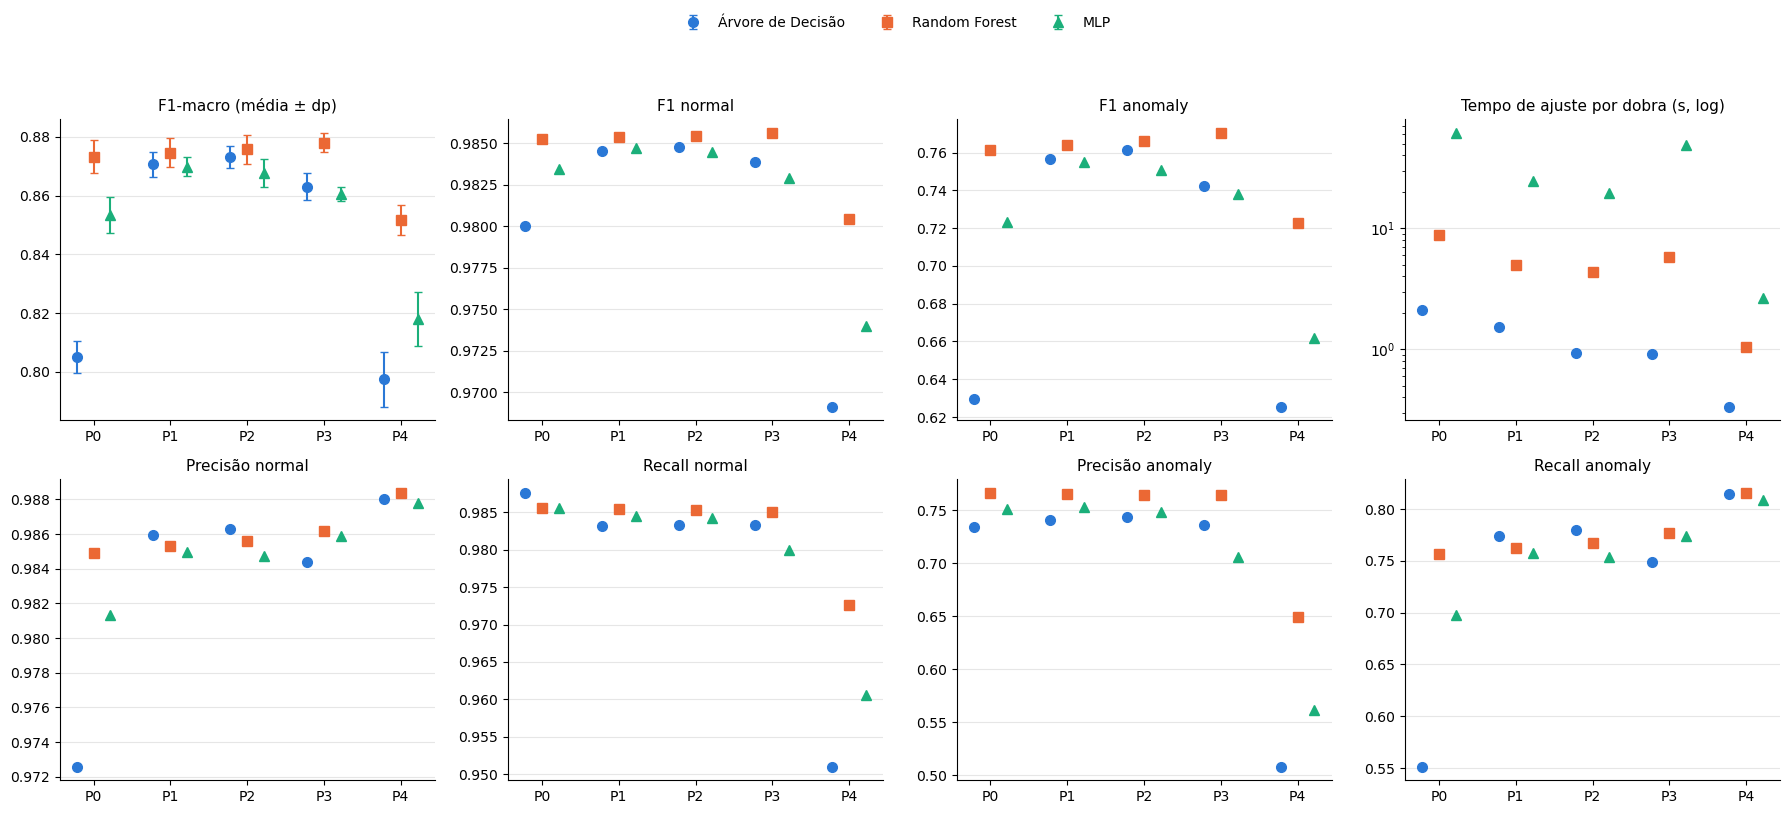

In [18]:
# Membro 4 - 4.2 Gráficos: F1-macro (média ± dp), precisão, recall e F1 por classe e tempo de ajuste
import matplotlib.pyplot as plt

# Paleta categórica validada para daltonismo (ΔE ≥ 8 entre pares); o marcador é a codificação secundária.
CORES_ALGORITMO = {"Árvore de Decisão": "#2a78d6", "Random Forest": "#eb6834", "MLP": "#1baf7a"}
MARCADORES_ALGORITMO = {"Árvore de Decisão": "o", "Random Forest": "s", "MLP": "^"}
PAINEIS = [("f1_macro_media", "F1-macro (média ± dp)"), ("f1_normal", "F1 normal"), ("f1_anomaly", "F1 anomaly"),
           ("seg_ajuste", "Tempo de ajuste por dobra (s, log)"),
           ("precisao_normal", "Precisão normal"), ("recall_normal", "Recall normal"),
           ("precisao_anomaly", "Precisão anomaly"), ("recall_anomaly", "Recall anomaly")]
tabela_principal = tabela_etapa3[tabela_etapa3.principal]
posicoes = np.arange(len(CONFIGURACOES))

fig, eixos = plt.subplots(2, 4, figsize=(18, 8), layout="constrained")
for eixo, (coluna, titulo) in zip(eixos.flat, PAINEIS):
    for j, (algoritmo, cor) in enumerate(CORES_ALGORITMO.items()):
        dados = tabela_principal[tabela_principal.algoritmo == algoritmo].set_index("configuracao").reindex(CONFIGURACOES)
        eixo.errorbar(posicoes + (j - 1) * 0.22, dados[coluna],
                      yerr=dados.f1_macro_dp if coluna == "f1_macro_media" else None,
                      fmt=MARCADORES_ALGORITMO[algoritmo], color=cor, markersize=7, capsize=3, elinewidth=1.5,
                      linestyle="none", label=algoritmo)
    eixo.set_xticks(posicoes, [n.split()[0] for n in CONFIGURACOES])
    eixo.set_title(titulo, fontsize=11)
    eixo.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    eixo.set_axisbelow(True)
    eixo.spines[["top", "right"]].set_visible(False)
    if coluna == "seg_ajuste":
        eixo.set_yscale("log")
fig.legend(*eixos.flat[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

### Resultados e justificativa - Membro 4

**Comparabilidade.** As 90 avaliações (18 candidatos × 5 dobras) passaram nas verificações de 4.1:
- mesmas dobras (assinatura `8a814c72d149c698`);
- mesma validação em cada dobra (13.966–13.968 linhas e 815–816 anomalias);
- mesmo treino filtrado para os três algoritmos em cada combinação e dobra.

Portanto, as diferenças da tabela vêm do algoritmo e do pré-processamento, não da divisão dos dados.

**Tabela principal.** F1-macro médio ± desvio nas 5 dobras; o melhor de cada algoritmo está em negrito:

| Combinação | Balanceamento | Árvore de Decisão | Random Forest | MLP (StandardScaler) |
|---|---|---:|---:|---:|
| P0 (R0) | nenhum | 0,8049 ± 0,0054 | 0,8733 ± 0,0057 | 0,8534 ± 0,0062 |
| P1 (M1) | nenhum | 0,8706 ± 0,0044 | 0,8746 ± 0,0049 | **0,8698 ± 0,0032** |
| P2 (M1 + raras agrupadas) | nenhum | **0,8730 ± 0,0038** | 0,8757 ± 0,0049 | 0,8677 ± 0,0049 |
| P3 (P2) | ROS 1:1 | 0,8630 ± 0,0045 | **0,8780 ± 0,0033** | 0,8605 ± 0,0023 |
| P4 (P2) | RUS 1:1 | 0,7973 ± 0,0092 | 0,8516 ± 0,0051 | 0,8180 ± 0,0093 |

Variantes complementares em P2: árvore com seleção aninhada, 0,8728 ± 0,0037; Random Forest com seleção aninhada, **0,8782 ± 0,0036**; MLP sem escala, 0,8225 ± 0,0107. A tabela completa, com precisão, recall e F1 por classe, acurácia, erros e tempos, está na saída de 4.1, no formato do roteiro do relatório.

**Ganhos.**
- **Random Forest é o melhor algoritmo nas 5 combinações e em todas as 25 dobras pareadas.** Os melhores de cada algoritmo são: floresta 0,878 (P3 ou aninhada em P2), árvore 0,873 (P2) e MLP 0,870 (P1). As diferenças entre os três são de 0,003 a 0,008.
- A classe `normal` tem F1 entre 0,983 e 0,986 para os três algoritmos em P1–P3. Quase toda a diferença está em `anomaly`:
  - a floresta equilibra precisão e recall (0,764 / 0,768 em P2);
  - a árvore troca precisão por recall (0,743 / 0,780);
  - a MLP fica abaixo nas duas (0,748 / 0,754).

**O pré-processamento interage com o algoritmo.** Nenhuma combinação é a melhor para todos:
- **Limpeza M1 (P0 → P1):** é decisiva para a árvore (+0,066) e importante para a MLP (+0,016), mas quase irrelevante para a floresta (+0,0013).
- **Categorias raras agrupadas (P1 → P2):** ajudam a árvore (+0,0024) e a floresta (+0,0011), mas não a MLP (−0,0021).
- **ROS (P2 → P3):** piora a árvore (−0,0100) e a MLP (−0,0072), mas melhora a floresta (+0,0023).
- **RUS:** piora os três. Leva o recall de `anomaly` a ~0,81, mas a precisão cai para 0,51–0,65 e os falsos positivos aumentam de cerca de 2 a 3 vezes.

Por isso, a comparação final precisa ser feita por par (algoritmo, combinação), e não fixando um único pré-processamento.

**Variabilidade.** O desvio entre dobras fica entre 0,002 e 0,005 em P1–P3. Ele é da mesma ordem das diferenças entre os candidatos do topo, então diferenças abaixo de ~0,003 entre médias não devem ser lidas como decisivas. A comparação pareada é mais informativa, porque as dobras são as mesmas: a floresta vence a árvore e a MLP em todas as dobras de todas as combinações.

**Custo.** Tempo de ajuste por dobra nesta máquina, com 28 núcleos:
- árvore: 0,3–1,7 s;
- floresta: 0,5–2,4 s, com paralelismo (cerca de 13 vezes a árvore com um núcleo, seção 2.5);
- MLP: 1–21 s; é a mais cara, sobretudo com ROS (mais linhas) e em P0 (mais colunas e mais épocas).

A predição leva menos de 0,1 s por dobra para todos. A acurácia (0,943–0,973) varia pouco entre candidatos e esconde as diferenças em `anomaly`. Por isso fica como métrica complementar.

**Limitações.**
- As mesmas dobras foram usadas na etapa 2 para escolher o pré-processamento e aqui para comparar algoritmos, o que torna as diferenças otimistas.
- A árvore e a floresta tiveram seleção aninhada de hiperparâmetros em P2. A MLP usou parâmetros fixados sem busca, então pode estar em desvantagem.
- Os tempos são de relógio e dependem da máquina e do paralelismo.
- Os sinais operacionais continuam excluídos, e o teste oficial não foi lido.

**Uso de IA.** A implementação, a execução e a redação desta seção tiveram apoio do Claude Code (Anthropic). O responsável deve revisar a interpretação e registrar sua contribuição efetiva antes da entrega.

## Membro 5 - Seleção e auditoria metodológica

**Tarefa:** Auditar a execução dos pipelines e escolher com a equipe o vencedor por validação interna, priorizando F1-macro. Registrar critério de desempate, configuração exata, sementes, versões e dados usados. Discutir o otimismo decorrente de selecionar o melhor resultado de várias tentativas.

**Entregável:** Justificativa do vencedor e configuração reproduzível para a etapa 4, sem nenhuma decisão guiada pelo teste oficial.


### 5.1 Critério de seleção

A regra de escolha do melhor modelo foi definida antes dos testes da Random Forest e das análises seguintes, sem ajustar os critérios aos resultados já conhecidos.

O principal critério foi o maior F1-macro médio nas cinco dobras, em caso de resultados muito próximos (diferença menor que 0,0005), usamos o F1 da classe anomaly como desempate e se necessário, usamos o menor tempo de treinamento.

Também realizamos análises adicionais para verificar a estabilidade dos resultados e a confiabilidade da escolha sem alterar o modelo selecionado.

### 5.2 Auditoria dos pipelines

Antes da escolha final, verificamos se todas as etapas seguiram corretamente o protocolo, conferimos os dados utilizados, os atributos dos modelos, as divisões por grupos e o processo de treinamento. Também garantimos que o filtro de conflitos, o preenchimento de dados ausentes e a reamostragem fossem aplicados somente aos dados de treino, sem interferir na validação ou utilizar o teste oficial.


In [19]:
# Membro 5 - 5.2 Auditoria metodológica dos pipelines (sem consultar o teste oficial)
import json
import matplotlib

verificacoes = {}

# Dados: impressão digital do arquivo; nenhuma seção alterou X_treino/y_treino em memória.
HASH_TREINO = hashlib.sha256((DIR_DADOS / "treino.csv").read_bytes()).hexdigest()
X_conferencia, y_conferencia = carregar_treino()
assert X_conferencia.equals(X_treino) and y_conferencia.equals(y_treino)
verificacoes["Dados: sha256 de treino.csv; objetos em memória iguais ao arquivo"] = HASH_TREINO[:16]

# Preditores: sem id, rótulo e sinais operacionais.
assert not set(SINAIS_OPERACIONAIS + [COL_ID, COL_ROTULO]).intersection(X_treino.columns)
verificacoes["Preditores: sem id, class e sinais operacionais"] = f"{X_treino.shape[1]} atributos"

# Dobras: mesma assinatura do Membro 1, partição completa e grupos disjuntos.
dobra_auditada = np.zeros(len(X_treino), dtype=int)
for i, (itr, iva) in enumerate(INDICES_DOBRAS, start=1):
    assert not np.intersect1d(itr, iva).size and len(itr) + len(iva) == len(X_treino)
    assert set(grupos_treino.iloc[itr]).isdisjoint(grupos_treino.iloc[iva])
    dobra_auditada[iva] = i
assert (dobra_auditada > 0).all()
assert hashlib.sha256(dobra_auditada.tobytes()).hexdigest()[:16] == ASSINATURA_DOBRAS
verificacoes["Dobras: mesma assinatura, partição completa, grupos disjuntos"] = ASSINATURA_DOBRAS

# Validação intacta em todos os candidatos (exigida pelo Membro 4 e refeita sobre a tabela final).
assert (por_dobra_etapa3[["TN", "FP", "FN", "TP"]].sum(axis=1) == por_dobra_etapa3.dobra.map(tamanho_validacao)).all()
verificacoes["Validação: todas as linhas, sem filtro nem reamostragem"] = f"{len(por_dobra_etapa3)} avaliações conferidas"

# Ajuste só no treino da dobra 1: o filtro remove apenas linhas do treino; as medianas do imputador são
# as do treino filtrado; o modelo recebe o treino reamostrado e a validação é prevista inteira.
itr, iva = INDICES_DOBRAS[0]
for nome_cfg, cfg in CONFIGURACOES.items():
    X_fit, y_fit = filtrar_linhas_treino(X_treino.iloc[itr], y_treino.iloc[itr], cfg["linhas_treino"])
    assert set(X_fit.index) <= set(X_treino.index[itr]) and not set(X_fit.index) & set(X_treino.index[iva])
    assert len(X_fit) == por_dobra_etapa3[(por_dobra_etapa3.configuracao == nome_cfg)
                                          & (por_dobra_etapa3.dobra == 1)].n_treino_ajuste.iloc[0]
    pipe = montar_pipeline(cfg, ARVORE_PADRAO).fit(X_fit, y_fit)
    imp = pipe.named_steps["imputacao_codificacao"].named_transformers_["num"].named_steps["imp"]
    np.testing.assert_allclose(imp.statistics_, pipe[:3].transform(X_fit)[imp.feature_names_in_].median().to_numpy())
    n_normal, n_anomaly = int((y_fit == 0).sum()), int((y_fit == 1).sum())
    esperado = {None: n_normal + n_anomaly, "ROS": 2 * n_normal, "RUS": 2 * n_anomaly}[cfg["balanceamento"]]
    assert pipe.named_steps["modelo"].tree_.n_node_samples[0] == esperado      # linhas que chegaram ao modelo
    assert len(pipe.predict(X_treino.iloc[iva])) == len(iva)
verificacoes["Ajuste só no treino: filtro, medianas e reamostragem (P0–P4, dobra 1)"] = "conferido"

# Teste oficial: nenhuma célula executada até aqui cita os arquivos de teste ou de submissão.
historico = globals().get("In", [])
alvos = ["teste_sem" + "_rotulo", "modelo_de" + "_submissao"]    # montados por partes para não casar com esta célula
assert len(historico) > 1 and not any(a in celula for celula in historico for a in alvos)
verificacoes["Teste oficial: nenhuma célula executada cita os arquivos de teste"] = f"{len(historico) - 1} células"

VERSOES = {"Python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
           "scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__,
           "matplotlib": matplotlib.__version__}
verificacoes["Sementes: dobras, amostradores e modelos"] = SEMENTE
verificacoes["Versões"] = ", ".join(f"{k} {v}" for k, v in VERSOES.items())
with pd.option_context("display.max_colwidth", 120):
    display(pd.Series(verificacoes, name="resultado").to_frame())

,resultado
Dados: sha256 de treino.csv; objetos em memória iguais ao arquivo,9713c75938ef1e9e
"Preditores: sem id, class e sinais operacionais",46 atributos
"Dobras: mesma assinatura, partição completa, grupos disjuntos",8a814c72d149c698
"Validação: todas as linhas, sem filtro nem reamostragem",90 avaliações conferidas
"Ajuste só no treino: filtro, medianas e reamostragem (P0–P4, dobra 1)",conferido
Teste oficial: nenhuma célula executada cita os arquivos de teste,19 células
"Sementes: dobras, amostradores e modelos",42
Versões,"Python 3.12.3, numpy 1.26.4, pandas 3.0.5, scikit-learn 1.9.0, imbalanced-learn 0.14.2, matplotlib 3.6.3"


### 5.3 Aplicação da regra de seleção

A regra 5.1 é aplicada à tabela do Membro 4, em seguida, comparamos o vencedor com cada um dos outros candidatos dobra a dobra, comparando diferença média, mínima e máxima de F1-macro e número de dobras em que o vencedor foi melhor.

Empatados com o líder no F1-macro (diferença < 0,0005): ['RF aninhada · P2', 'RF · P3']
Ainda empatados após o critério do F1 de anomaly (diferença < 0,0005): ['RF aninhada · P2', 'RF · P3']
Desempate final pelo menor tempo médio de ajuste (s/dobra): {'RF aninhada · P2': 7.91, 'RF · P3': 5.81}
Vencedor: RF · P3 - Random Forest (parâmetros fixados, escala nenhuma), P3 P2 + ROS: F1-macro 0.8780 ± 0.0033


,rotulo,algoritmo,variante,escala,configuracao,f1_macro_media,f1_macro_dp,dif_para_lider,f1_anomaly,precisao_anomaly,recall_anomaly,seg_ajuste
1,RF aninhada · P2,Random Forest,seleção aninhada,nenhuma,P2 P1 + raras agrupadas,0.8782,0.0036,0.0000,0.7707,0.7637,0.7779,7.9148
2,RF · P3,Random Forest,parâmetros fixados,nenhuma,P3 P2 + ROS,0.8780,0.0033,-0.0002,0.7704,0.7640,0.7769,5.8122
3,RF · P2,Random Forest,parâmetros fixados,nenhuma,P2 P1 + raras agrupadas,0.8757,0.0049,-0.0025,0.7660,0.7644,0.7676,4.3311
4,RF · P1,Random Forest,parâmetros fixados,nenhuma,P1 tratamento M1,0.8746,0.0049,-0.0035,0.7639,0.7651,0.7627,4.9639
5,RF · P0,Random Forest,parâmetros fixados,nenhuma,P0 referência R0,0.8733,0.0057,-0.0049,0.7613,0.7660,0.7568,8.8338
6,Árvore · P2,Árvore de Decisão,parâmetros padrão,nenhuma,P2 P1 + raras agrupadas,0.8730,0.0038,-0.0052,0.7612,0.7434,0.7801,0.9375
7,Árvore aninhada · P2,Árvore de Decisão,seleção aninhada,nenhuma,P2 P1 + raras agrupadas,0.8728,0.0037,-0.0054,0.7607,0.7436,0.7789,0.8734
8,Árvore · P1,Árvore de Decisão,parâmetros padrão,nenhuma,P1 tratamento M1,0.8706,0.0044,-0.0075,0.7567,0.7402,0.7742,1.5234
9,MLP · P1,MLP,parâmetros fixados,StandardScaler,P1 tratamento M1,0.8698,0.0032,-0.0084,0.7549,0.7525,0.7573,24.7704
10,MLP · P2,MLP,parâmetros fixados,StandardScaler,P2 P1 + raras agrupadas,0.8677,0.0049,-0.0105,0.7509,0.7482,0.7539,19.6923


Vencedor (RF · P3) − cada candidato, por dobra (5 dobras):


,dif_media,dif_min,dif_max,dobras_vencedor_melhor
rotulo,,,,
RF aninhada · P2,-0.0002,-0.0014,0.0021,1
RF · P2,0.0023,0.0000,0.0048,5
RF · P1,0.0034,0.0013,0.0056,5
RF · P0,0.0047,0.0018,0.0078,5
Árvore · P2,0.0050,0.0036,0.0061,5
Árvore aninhada · P2,0.0052,0.0036,0.0066,5
Árvore · P1,0.0074,0.0045,0.0098,5
MLP · P1,0.0082,0.0048,0.0109,5
MLP · P2,0.0103,0.0086,0.0157,5


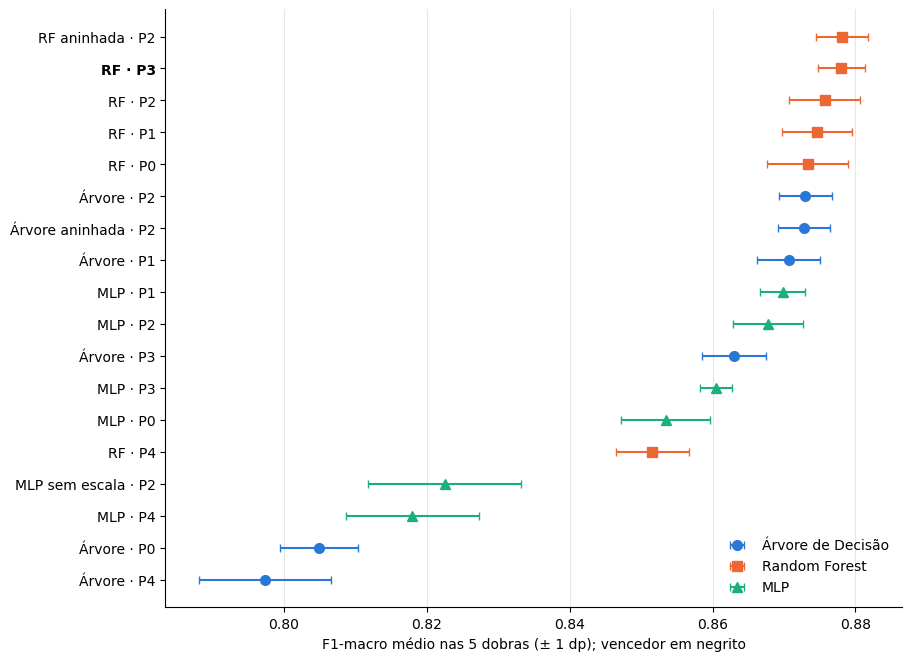

In [20]:
# Membro 5 - 5.3 Aplicação da regra de seleção declarada em 5.1
LIMIAR_EMPATE = 0.0005
ranking = (tabela_etapa3.sort_values(["f1_macro_media", "f1_anomaly", "seg_ajuste"], ascending=[False, False, True])
           .reset_index(drop=True))
ranking["dif_para_lider"] = ranking.f1_macro_media - ranking.f1_macro_media.iloc[0]
# Passo 2: empatados com o líder no F1-macro; passo 3: maior F1 de anomaly e, persistindo, menor tempo.
empatados = ranking[ranking.dif_para_lider > -LIMIAR_EMPATE]
empatados_anomaly = empatados[empatados.f1_anomaly > empatados.f1_anomaly.max() - LIMIAR_EMPATE]
vencedor = empatados_anomaly.sort_values("seg_ajuste").iloc[0]
print("Empatados com o líder no F1-macro (diferença < 0,0005):", empatados.rotulo.tolist())
if len(empatados) > 1:
    print("Ainda empatados após o critério do F1 de anomaly (diferença < 0,0005):", empatados_anomaly.rotulo.tolist())
if len(empatados_anomaly) > 1:
    print("Desempate final pelo menor tempo médio de ajuste (s/dobra):",
          empatados_anomaly.set_index("rotulo").seg_ajuste.round(2).to_dict())
print(f"Vencedor: {vencedor.rotulo} - {vencedor.algoritmo} ({vencedor.variante}, escala {vencedor.escala}), "
      f"{vencedor.configuracao}: F1-macro {vencedor.f1_macro_media:.4f} ± {vencedor.f1_macro_dp:.4f}")

with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250, "display.max_rows", 30):
    display(ranking[["rotulo", "algoritmo", "variante", "escala", "configuracao", "f1_macro_media", "f1_macro_dp",
                     "dif_para_lider", "f1_anomaly", "precisao_anomaly", "recall_anomaly", "seg_ajuste"]]
            .rename(index=lambda i: i + 1))

# Diferenças pareadas por dobra: vencedor − cada candidato.
f1_por_dobra = por_dobra_etapa3.pivot(index="dobra", columns="rotulo", values="f1_macro")
dif_vencedor = f1_por_dobra.rsub(f1_por_dobra[vencedor.rotulo], axis=0).drop(columns=vencedor.rotulo)
pareado_vencedor = pd.DataFrame({"dif_media": dif_vencedor.mean(), "dif_min": dif_vencedor.min(),
                                 "dif_max": dif_vencedor.max(), "dobras_vencedor_melhor": (dif_vencedor > 0).sum()})
print(f"Vencedor ({vencedor.rotulo}) − cada candidato, por dobra (5 dobras):")
display(pareado_vencedor.sort_values("dif_media").round(4))

# Visão geral do ranking: F1-macro médio ± dp de todos os candidatos, cor e marcador por algoritmo.
ordem_grafico = ranking.iloc[::-1].reset_index(drop=True)     # melhor no topo
fig, eixo = plt.subplots(figsize=(9, 6.5), layout="constrained")
for algoritmo, cor in CORES_ALGORITMO.items():
    parte = ordem_grafico[ordem_grafico.algoritmo == algoritmo]
    eixo.errorbar(parte.f1_macro_media, parte.index, xerr=parte.f1_macro_dp, fmt=MARCADORES_ALGORITMO[algoritmo],
                  color=cor, markersize=7, capsize=3, elinewidth=1.5, linestyle="none", label=algoritmo)
eixo.set_yticks(ordem_grafico.index, ordem_grafico.rotulo)
eixo.get_yticklabels()[int(np.flatnonzero(ordem_grafico.rotulo == vencedor.rotulo)[0])].set_fontweight("bold")
eixo.set_xlabel("F1-macro médio nas 5 dobras (± 1 dp); vencedor em negrito")
eixo.grid(axis="x", color="#e6e6e6", linewidth=0.8)
eixo.set_axisbelow(True)
eixo.spines[["top", "right"]].set_visible(False)
eixo.legend(loc="lower right", frameon=False)
plt.show()

### 5.4 Estabilidade em outra divisão e otimismo da seleção

**Estabilidade:** Reavaliamos o modelo vencedor e os melhores modelos dos outros dois algoritmos usando uma nova divisão em cinco dobras, com semente 137. O objetivo foi verificar se os resultados continuavam semelhantes e se a ordem entre os modelos mudava, não alterando nenhum parâmetro. Como os mesmos dados foram utilizados a avaliação não é totalmente independente.

**Otimismo:** Também analisamos se a escolha do melhor modelo poderia ter sido favorecida pelos resultados das mesmas dobras e para isso, utilizamos dois métodos a correção de Tibshirani e Tibshirani (2009) e a seleção deixando uma dobra de fora. 

Ambos ajudam a estimar o quanto o desempenho do modelo escolhido pode estar acima do esperado. São estimativas aproximadas, pois as dobras não são totalmente independentes.



In [21]:
# Membro 5 - 5.4 Estabilidade na divisão 137 (sem nova escolha) e estimativas do otimismo da seleção
ESPECIFICACOES = {   # (algoritmo, variante, escala) -> como reconstruir o candidato
    ("Árvore de Decisão", "parâmetros padrão", "nenhuma"): dict(modelo=ARVORE_PADRAO, escala=None, grade=None),
    ("Árvore de Decisão", "seleção aninhada", "nenhuma"): dict(modelo=ARVORE_PADRAO, escala=None, grade=GRADE_ARVORE),
    ("Random Forest", "parâmetros fixados", "nenhuma"): dict(modelo=RF_BASE, escala=None, grade=None),
    ("Random Forest", "seleção aninhada", "nenhuma"): dict(modelo=RF_BASE, escala=None, grade=GRADE_RF),
    ("MLP", "parâmetros fixados", "StandardScaler"): dict(modelo=modelo_mlp_m3, escala="standard", grade=None),
    ("MLP", "parâmetros fixados", "nenhuma"): dict(modelo=modelo_mlp_m3, escala=None, grade=None),
}
assert set(ESPECIFICACOES) == set(map(tuple, tabela_etapa3[["algoritmo", "variante", "escala"]].to_numpy()))


def avaliar_candidato(linha, dobras):
    """Reavalia um candidato da tabela do Membro 4 em outras dobras, sem nova escolha de configuração."""
    esp = ESPECIFICACOES[(linha.algoritmo, linha.variante, linha.escala)]
    if esp["grade"] is None:
        res, _ = avaliar_modelo(esp["modelo"], linha.rotulo, {linha.configuracao: CONFIGURACOES[linha.configuracao]},
                                dobras=dobras, escala=esp["escala"])
    else:
        res, _ = selecao_aninhada(esp["modelo"], esp["grade"], linha.rotulo, linha.configuracao,
                                  dobras=dobras, escala=esp["escala"])
    return res


SEMENTE_ESTABILIDADE = 137
DOBRAS_137 = list(StratifiedGroupKFold(n_splits=N_DOBRAS, shuffle=True, random_state=SEMENTE_ESTABILIDADE)
                  .split(X_treino, y_treino, grupos_treino))
for itr, iva in DOBRAS_137:
    assert set(grupos_treino.iloc[itr]).isdisjoint(grupos_treino.iloc[iva])

# O vencedor e o melhor candidato de cada um dos outros algoritmos, pela mesma ordenação da regra.
reavaliados = [vencedor] + [ranking[ranking.algoritmo == a].iloc[0] for a in ORDEM_ALGORITMOS if a != vencedor.algoritmo]
inicio = time.perf_counter()
linhas_137, por_dobra_137 = [], []
for linha in reavaliados:
    with warnings.catch_warnings(record=True) as capturados:
        warnings.simplefilter("always")
        res = avaliar_candidato(linha, DOBRAS_137)
    por_dobra_137.append(res.assign(rotulo=linha.rotulo))
    linhas_137.append({"rotulo": linha.rotulo, "f1_macro_42": linha.f1_macro_media, "dp_42": linha.f1_macro_dp,
                       "f1_macro_137": res.f1_macro.mean(), "dp_137": res.f1_macro.std(),
                       "f1_anomaly_42": linha.f1_anomaly, "f1_anomaly_137": res.f1_anomaly.mean(),
                       "avisos_convergencia": sum(issubclass(a.category, ConvergenceWarning) for a in capturados)})
print(f"Reavaliação na divisão 137 concluída em {time.perf_counter() - inicio:.0f} s.")
estabilidade = pd.DataFrame(linhas_137)
estabilidade["f1_macro_duas_divisoes"] = (estabilidade.f1_macro_42 + estabilidade.f1_macro_137) / 2
por_dobra_137 = pd.concat(por_dobra_137, ignore_index=True)
f1_137 = por_dobra_137.pivot(index="dobra", columns="rotulo", values="f1_macro")
dif_137 = f1_137.rsub(f1_137[vencedor.rotulo], axis=0).drop(columns=vencedor.rotulo)
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250):
    display(estabilidade)
    print(f"Divisão 137 - vencedor ({vencedor.rotulo}) − cada candidato, por dobra:")
    display(pd.DataFrame({"dif_media": dif_137.mean(), "dobras_vencedor_melhor": (dif_137 > 0).sum()}))

# (a) Tibshirani e Tibshirani (2009): excesso médio do melhor candidato de cada dobra sobre o vencedor.
melhor_da_dobra = f1_por_dobra.max(axis=1)
vies_selecao = (melhor_da_dobra - f1_por_dobra[vencedor.rotulo]).mean()
# (b) Seleção deixando uma dobra de fora: escolhe pela média das outras quatro e mede só na dobra deixada de fora.
selecao_fora = pd.DataFrame([{"dobra": k, "escolhido_pelas_outras_4": f1_por_dobra.drop(index=k).mean().idxmax(),
                              "melhor_nesta_dobra": f1_por_dobra.loc[k].idxmax(),
                              "f1_macro_melhor": melhor_da_dobra[k]} for k in f1_por_dobra.index])
selecao_fora["f1_macro_escolhido"] = [f1_por_dobra.loc[k, c] for k, c in
                                      zip(selecao_fora.dobra, selecao_fora.escolhido_pelas_outras_4)]
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250):
    display(selecao_fora)
otimismo = pd.Series({
    "F1-macro do vencedor (máximo das médias)": round(vencedor.f1_macro_media, 4),
    "Viés estimado (Tibshirani e Tibshirani)": round(vies_selecao, 4),
    "F1-macro corrigido (máximo − viés)": round(vencedor.f1_macro_media - vies_selecao, 4),
    "F1-macro da seleção deixando uma dobra de fora": round(selecao_fora.f1_macro_escolhido.mean(), 4),
    "Candidatos comparados": f1_por_dobra.shape[1],
    "Dobras em que o vencedor é o melhor candidato": int((f1_por_dobra.idxmax(axis=1) == vencedor.rotulo).sum()),
}, name="valor", dtype=object)
display(otimismo.to_frame())

Reavaliação na divisão 137 concluída em 168 s.


,rotulo,f1_macro_42,dp_42,f1_macro_137,dp_137,f1_anomaly_42,f1_anomaly_137,avisos_convergencia,f1_macro_duas_divisoes
0,RF · P3,0.8780,0.0033,0.8760,0.0034,0.7704,0.7666,0,0.8770
1,Árvore · P2,0.8730,0.0038,0.8707,0.0035,0.7612,0.7569,0,0.8719
2,MLP · P1,0.8698,0.0032,0.8694,0.0065,0.7549,0.7541,0,0.8696


Divisão 137 - vencedor (RF · P3) − cada candidato, por dobra:


,dif_media,dobras_vencedor_melhor
rotulo,,
MLP · P1,0.0067,4
Árvore · P2,0.0053,5


,dobra,escolhido_pelas_outras_4,melhor_nesta_dobra,f1_macro_melhor,f1_macro_escolhido
0,1,RF aninhada · P2,RF · P3,0.8767,0.8746
1,2,RF · P3,RF aninhada · P2,0.8811,0.8801
2,3,RF aninhada · P2,RF aninhada · P2,0.8828,0.8828
3,4,RF · P3,RF aninhada · P2,0.8752,0.8738
4,5,RF aninhada · P2,RF aninhada · P2,0.8771,0.8771


,valor
F1-macro do vencedor (máximo das médias),0.878
Viés estimado (Tibshirani e Tibshirani),0.0006
F1-macro corrigido (máximo − viés),0.8774
F1-macro da seleção deixando uma dobra de fora,0.8777
Candidatos comparados,18
Dobras em que o vencedor é o melhor candidato,1


### 5.5 Configuração reproduzível para a etapa 4

Criamos o CONFIG_VENCEDOR_ETAPA3 para reunir todas as informações necessárias para reconstruir o modelo vencedor, incluindo os dados utilizados, o pré-processamento, os parâmetros do modelo, as sementes e as versões das bibliotecas.

A função construir_pipeline_vencedor() utiliza essas informações para montar o modelo novamente e para verificar se tudo estava correto, reconstruímos o modelo do zero na primeira dobra e comparamos sua matriz de confusão com a do resultado original. O treinamento completo e os testes oficiais ficam para a etapa 4.


In [22]:
# Membro 5 - 5.5 Configuração reproduzível do vencedor e verificação de reconstrução
esp_vencedor = ESPECIFICACOES[(vencedor.algoritmo, vencedor.variante, vencedor.escala)]
cfg_vencedor = CONFIGURACOES[vencedor.configuracao]
if esp_vencedor["grade"] is None:
    modelo_final = clone(esp_vencedor["modelo"])
    origem_parametros = "fixados antes da execução"
else:
    # Mesmo procedimento interno da seleção aninhada, agora sobre todo o treino (3 dobras por grupos, semente 42).
    melhor_final, _ = escolher_parametros(esp_vencedor["modelo"], esp_vencedor["grade"], vencedor.configuracao,
                                          X_treino, y_treino, grupos_treino, esp_vencedor["escala"])
    modelo_final = clone(esp_vencedor["modelo"]).set_params(**melhor_final)
    origem_parametros = f"seleção interna em todo o treino (3 dobras por grupos, semente {SEMENTE}): {melhor_final}"

CLASSES_MODELO = {c.__name__: c for c in (DecisionTreeClassifier, RandomForestClassifier, MLPClassifier)}
CONFIG_VENCEDOR_ETAPA3 = {
    "candidato": vencedor.rotulo,
    "algoritmo": vencedor.algoritmo,
    "classe_modelo": type(modelo_final).__name__,
    "parametros_modelo": modelo_final.get_params(deep=False),
    "origem_parametros": origem_parametros,
    "combinacao": vencedor.configuracao,
    "pre_processamento": {k: v for k, v in cfg_vencedor.items() if k not in ("linhas_treino", "balanceamento")},
    "escala": esp_vencedor["escala"],
    "linhas_treino": cfg_vencedor["linhas_treino"],
    "balanceamento": cfg_vencedor["balanceamento"],
    "colunas_fora_dos_preditores": [COL_ID, COL_ROTULO, *SINAIS_OPERACIONAIS],
    "dados": {"arquivo": "data/treino.csv", "sha256": HASH_TREINO, "linhas": len(X_treino),
              "atributos": X_treino.shape[1]},
    "sementes": {"dobras": SEMENTE, "amostradores": SEMENTE, "modelo": SEMENTE},
    "validacao_interna": {"esquema": f"StratifiedGroupKFold(n_splits={N_DOBRAS}, shuffle=True, random_state={SEMENTE}), "
                                     "grupos = registros com atributos idênticos",
                          "assinatura_dobras": ASSINATURA_DOBRAS,
                          "f1_macro_media": round(float(vencedor.f1_macro_media), 4),
                          "f1_macro_dp": round(float(vencedor.f1_macro_dp), 4)},
    "versoes": VERSOES,
}


def construir_pipeline_vencedor(config=CONFIG_VENCEDOR_ETAPA3):
    """Pipeline não ajustado do vencedor, montado apenas a partir do dicionário de configuração.

    Uso na etapa 4: X, y = carregar_treino(); X_fit, y_fit = filtrar_linhas_treino(X, y, config["linhas_treino"]);
    construir_pipeline_vencedor(config).fit(X_fit, y_fit). O conjunto previsto nunca é filtrado nem reamostrado.
    """
    modelo = CLASSES_MODELO[config["classe_modelo"]](**config["parametros_modelo"])
    cfg = {**config["pre_processamento"], "linhas_treino": config["linhas_treino"],
           "balanceamento": config["balanceamento"]}
    return montar_pipeline(cfg, modelo, escala=config["escala"])


# Reconstrução do zero na dobra 1 e comparação com o registrado na seleção.
itr, iva = INDICES_DOBRAS[0]
registrado = por_dobra_etapa3[(por_dobra_etapa3.rotulo == vencedor.rotulo) & (por_dobra_etapa3.dobra == 1)].iloc[0]
if esp_vencedor["grade"] is None:
    X_fit, y_fit = filtrar_linhas_treino(X_treino.iloc[itr], y_treino.iloc[itr], CONFIG_VENCEDOR_ETAPA3["linhas_treino"])
    pred = construir_pipeline_vencedor().fit(X_fit, y_fit).predict(X_treino.iloc[iva])
    reconstruido = metricas_classificacao(y_treino.iloc[iva], pred)
else:
    # Variante aninhada: a dobra 1 é reconstruída com o procedimento completo (escolha interna + ajuste).
    reconstruido = selecao_aninhada(esp_vencedor["modelo"], esp_vencedor["grade"], vencedor.rotulo,
                                    vencedor.configuracao, dobras=[(itr, iva)], escala=esp_vencedor["escala"])[0].iloc[0]
matriz = ["TN", "FP", "FN", "TP"]
assert [int(reconstruido[c]) for c in matriz] == [int(registrado[c]) for c in matriz]
assert construir_pipeline_vencedor().named_steps["modelo"].get_params() == modelo_final.get_params()

print(json.dumps(CONFIG_VENCEDOR_ETAPA3, indent=2, ensure_ascii=False, default=str))
display(pd.DataFrame({"registrado na seleção": [int(registrado[c]) for c in matriz] + [round(registrado.f1_macro, 4)],
                      "reconstruído do dicionário": [int(reconstruido[c]) for c in matriz]
                                                    + [round(reconstruido["f1_macro"], 4)]},
                     index=matriz + ["f1_macro"], dtype=object).T)
print("Reconstrução aprovada: o dicionário reproduz a dobra 1 do vencedor.")

{
  "candidato": "RF · P3",
  "algoritmo": "Random Forest",
  "classe_modelo": "RandomForestClassifier",
  "parametros_modelo": {
    "bootstrap": true,
    "ccp_alpha": 0.0,
    "class_weight": null,
    "criterion": "gini",
    "max_depth": null,
    "max_features": "sqrt",
    "max_leaf_nodes": null,
    "max_samples": null,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 1,
    "min_samples_split": 2,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": null,
    "n_estimators": 300,
    "n_jobs": -1,
    "oob_score": false,
    "random_state": 42,
    "verbose": 0,
    "warm_start": false
  },
  "origem_parametros": "fixados antes da execução",
  "combinacao": "P3 P2 + ROS",
  "pre_processamento": {
    "normalizar_categorias": true,
    "fora_dominio": "ausente",
    "remover_redundantes": true,
    "imputacao_num": "mediana",
    "imputacao_cat": "constante",
    "codificacao": "onehot_raras"
  },
  "escala": null,
  "linhas_treino": "sem_conflitos",
  "balanceame

,TN,FP,FN,TP,f1_macro
registrado na seleção,12953,198,184,632,0.8767
reconstruído do dicionário,12953,198,184,632,0.8767


Reconstrução aprovada: o dicionário reproduz a dobra 1 do vencedor.


### 5.6 Resultados e justificativa - Membro 5

**Auditoria (5.2).** Todas as verificações passaram:
- `treino.csv` tem sha256 `7d0ca986…` e os objetos em memória são iguais ao arquivo;
- os 46 preditores não incluem `id`, `class` nem os três sinais operacionais;
- as dobras têm a assinatura `8a814c72d149c698`, formam uma partição completa e têm grupos disjuntos;
- as 90 avaliações usaram a validação inteira;
- na dobra 1 de P0–P4, o filtro remove apenas linhas do treino, as medianas do imputador são as do treino filtrado e o modelo recebe exatamente o número de linhas esperado após ROS/RUS;
- nenhuma célula executada cita os arquivos de teste ou de submissão.

**Vencedor (5.3).** A regra de 5.1 foi aplicada sem alterações:
1. O líder em F1-macro é a Random Forest com seleção aninhada em P2: **0,8782 ± 0,0036**.
2. A Random Forest fixada em P3 (ROS) fica a 0,0002 (0,8780 ± 0,0033), abaixo do limite de 0,0005, e conta como empate.
3. O F1 de `anomaly` também empata (0,7707 contra 0,7704).
4. O desempate final é o tempo médio de ajuste: ~2,0 s contra ~2,2 s por dobra.

O tempo da variante aninhada mede o ajuste final em cada dobra, sem a busca interna. Na etapa 4, essa busca é feita uma única vez, e já foi executada em 5.5.

Esse último critério usa tempos de relógio, que variam entre máquinas e execuções: aqui a diferença foi de cerca de 9%. Uma reexecução em outra máquina pode inverter o desempate. Isso não muda a conclusão: os dois empatados são florestas equivalentes em F1-macro e em F1 de `anomaly`. O vencedor é também o mais simples dos dois: não duplica linhas, e `max_features=0.3` foi escolhido pela validação interna em todas as dobras.

**Configuração vencedora:**
- **Algoritmo:** `RandomForestClassifier(n_estimators=300, max_features=0.3, min_samples_leaf=1, max_depth=None, class_weight=None, bootstrap=True, random_state=42, n_jobs=-1)`.
- **Pré-processamento:** combinação P2, com categorias normalizadas, valores fora do domínio como ausentes, remoção de derivadas e constantes, mediana numérica, categoria `__ausente__`, filtro de conflitos só no treino e One-Hot com categorias raras agrupadas.
- **Balanceamento e escala:** nenhum.
- **Colunas fora dos preditores:** `id` e os três sinais operacionais.

**Força da evidência (5.3–5.4).**
- **Comparação pareada:** o vencedor supera, nas 5 dobras, 16 dos 17 outros candidatos, inclusive a melhor árvore (P2, +0,0052) e a melhor MLP (P1, +0,0084). Contra a floresta com ROS, a diferença média é +0,0002 (de −0,0021 a +0,0014 por dobra), um empate prático.
- **Divisão 137:** sem nova escolha, a ordem dos algoritmos se mantém. A floresta tem 0,8772 ± 0,0036, a árvore 0,8707 e a MLP 0,8694. O vencedor supera a árvore em 5/5 dobras e a MLP em 4/5.
- **Otimismo da seleção:** a correção de Tibshirani e Tibshirani estima um viés de 0,0004, o que dá 0,8777. A seleção deixando uma dobra de fora também obtém 0,8777. O viés é pequeno por dois motivos: o vencedor é o melhor candidato em 4 das 5 dobras, e o único concorrente próximo é outra floresta.

Essas estimativas cobrem apenas a escolha entre os 18 candidatos deste notebook. As decisões da etapa 2 (filtro de conflitos, agrupamento de categorias, exclusão dos sinais) também foram tomadas sobre estas dobras, e a divisão 137 já foi consultada naquela etapa. Esse otimismo acumulado não foi quantificado. Uma expectativa prudente para dados do mesmo processo é um F1-macro um pouco abaixo de 0,878. O desempenho no teste oficial é desconhecido e será informado pela professora. Como mostraram as seções 1.5 e 2.5, a maior parte dos erros está nos grupos conflitantes, que formam um piso para qualquer classificador.

**Reprodutibilidade (5.5).** `CONFIG_VENCEDOR_ETAPA3` registra dados (sha256), colunas excluídas, pré-processamento, filtro, balanceamento, escala, classe e parâmetros do modelo, sementes, protocolo de validação e versões. Repetida sobre todo o treino, a busca interna escolheu de novo `max_features=0.3, min_samples_leaf=1, class_weight=None`. Reconstruído apenas a partir do dicionário, o pipeline reproduziu exatamente a dobra 1 da seleção: TN 12.951, FP 200, FN 188, TP 628, F1-macro 0,8746. O resultado da floresta não depende do número de núcleos (seção 2.5).

Roteiro para a etapa 4:
1. Carregar o treino sem os sinais operacionais.
2. Aplicar `filtrar_linhas_treino(X, y, "sem_conflitos")` a todo o treino.
3. Ajustar `construir_pipeline_vencedor()`.
4. Prever o teste sem filtrar nem reamostrar.

As classes da seção 1.1 (`NormalizarCategorias`, `TratarForaDominio`, `RemoverRedundantes`, `montar_preprocessamento`) precisam ser definidas no notebook 04, para que ele não dependa de objetos deste notebook.

**Limitações e pendências.**
- A escolha segue uma regra declarada, mas deve ser confirmada pela equipe na revisão conjunta.
- A exclusão dos sinais operacionais é preventiva. Se a professora confirmar que estão disponíveis no momento da predição, a comparação precisa ser refeita.
- Nenhuma métrica do teste oficial foi usada ou produzida.

**Uso de IA.** A implementação, a execução e a redação desta seção tiveram apoio do Claude Code (Anthropic). O responsável deve revisar a interpretação e registrar sua contribuição efetiva antes da entrega.

## Revisão conjunta

Cada membro deve explicar sua contribuição e revisar a integração com os demais. Conferir os requisitos da etapa, resultados reais, ausência de vazamento, reprodução e declaração de uso de IA antes de entregar.
